<a href="https://colab.research.google.com/github/KMINNNNJ/LG-K-NewDeal-Practice/blob/main/LG_AI4I_2020_8Modules_SmartFactory_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LG전자 스마트팩토리 — AI4I 2020 설비 이상감지·예지보전 실습

**32장 슬라이드 연계 · Module 1~8 · Google Colab 실행용**

학습 경로: **Data → EDA → Physics → Rules → Machine Learning → Evaluation → Dashboard → Capstone**

> **중요:** UCI AI4I 2020은 **합성된 제조 공정 관측치**입니다. 실제 소형 냉각팬 P04 기능검사 설비에서 수집한 데이터가 아닙니다. `Machine failure`는 해당 행의 고장 *분류 레이블*이며, 미래 고장 시점이나 RUL의 정답은 제공하지 않습니다. 행 순서를 실제 설비의 시간축으로 간주해 조기경보 리드타임이나 MA20 성능을 주장하지 않습니다.

**데이터 출처:** UCI AI4I 2020 Predictive Maintenance Dataset, ID 601, DOI: [10.24432/C5HS5C](https://doi.org/10.24432/C5HS5C), CC BY 4.0. [원본 페이지](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

**사용법:** 런타임 → 모두 실행. 데이터 인터넷 연결 오류 발생 시 2번 셀에서 CSV 수동 업로드를 사용합니다. 머신러닝 결과는 실행할 때마다 실데이터로 산출됩니다.

## 준비 · 설치 및 공통 설정

Colab에서는 첫 셀 설치 후 런타임 재시작을 요구할 수 있습니다. 이 경우 다시 순서대로 실행합니다.

In [6]:
%pip -q install -U ucimlrepo "pandas<3.0.0" "numpy>2.0.0" matplotlib plotly scikit-learn joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


In [147]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
import joblib

RANDOM_STATE = 42
ROOT = Path('/content/ai4i_colab') if Path('/content').exists() else Path('/mnt/data/ai4i_colab')
ROOT.mkdir(parents=True, exist_ok=True)
print('Output folder:', ROOT)

Output folder: /content/ai4i_colab


## Module 1 (Slides 1–4) · 데이터 이해와 데이터 사전

**수행:** ① 원본 10,000행 다운로드 ② 컬럼 확인 ③ 식별자/입력/정답 구분 ④ 고장 유형 분포 확인.

UCI 원본 데이터는 `ucimlrepo.fetch_ucirepo(id=601)`를 사용합니다. **다운로드가 안 되면** UCI 웹사이트에서 `ai4i2020.csv`를 받아 Colab에 업로드하세요.

In [148]:
CSV = ROOT / 'ai4i2020.csv'
if CSV.exists():
    print('기존 로컬 데이터 사용:', CSV)
    df = pd.read_csv(CSV)
else:
    try:
        # 원본 14개 컬럼을 보존하는 UCI CSV 경로 사용
        import requests, io
        url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv'
        r = requests.get(url, timeout=25)
        r.raise_for_status()
        df = pd.read_csv(io.BytesIO(r.content))
        df.to_csv(CSV, index=False)
        print('UCI 원본 CSV 다운로드 성공')
    except Exception as e:
        print('온라인 데이터 접근 실패:', str(e)[:220])
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError('이 환경에서는 먼저 ai4i2020.csv를 지정된 경로에 저장하세요.') from exc
        print('UCI에서 ai4i2020.csv를 내려받은 후 아래 업로드 창에 제출하세요.')
        uploaded = files.upload()
        selected = next((name for name in uploaded if name.lower().endswith('.csv')), None)
        if selected is None:
            raise RuntimeError('CSV 파일이 업로드되지 않았습니다.')
        df = pd.read_csv(selected)
        df.to_csv(CSV, index=False)

EXPECTED = ['UDI','Product ID','Type','Air temperature [K]','Process temperature [K]',
            'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]','Machine failure',
            'TWF','HDF','PWF','OSF','RNF']
missing = set(EXPECTED) - set(df.columns)
assert not missing, f'필수 컬럼 누락: {missing}'
assert len(df) == 10000, f'행 수 검증 실패: {len(df)}'
df = df[EXPECTED].copy()
print('shape:', df.shape)
display(df.head())

기존 로컬 데이터 사용: /content/ai4i_colab/ai4i2020.csv
shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [149]:
dictionary = pd.DataFrame([
    ('UDI','식별자','레코드 식별번호','-'),('Product ID','식별자','제품 식별번호','-'),
    ('Type','입력','제품 등급 L/M/H','-'),('Air temperature [K]','입력','공기 온도','K'),
    ('Process temperature [K]','입력','공정 온도','K'),('Rotational speed [rpm]','입력','회전속도','rpm'),
    ('Torque [Nm]','입력','토크','Nm'),('Tool wear [min]','입력','공구 마모 누적시간','min'),
    ('Machine failure','정답','행의 고장 여부','0/1'),
    ('TWF','정답','공구 마모 고장','0/1'),('HDF','정답','열 방출 고장','0/1'),
    ('PWF','정답','동력 고장','0/1'),('OSF','정답','과도 하중 고장','0/1'),
    ('RNF','정답','무작위 고장','0/1')], columns=['컬럼','구분','의미','단위'])
display(dictionary)
dictionary.to_csv(ROOT/'data_dictionary.csv', index=False, encoding='utf-8-sig')
print('고장 유형 플래그 합계 (동시 발생 가능):')
display(df[['TWF','HDF','PWF','OSF','RNF']].sum().to_frame('count').T)
# 원본 데이터에는 Machine failure와 고장 종류 플래그 사이의 소수 불일치가 있을 수 있음
mismatch = ((df[['TWF','HDF','PWF','OSF','RNF']].max(axis=1) != df['Machine failure'])).sum()
print('고장 유형 플래그와 전체 고장 레이블의 불일치 행:', mismatch)

,컬럼,구분,의미,단위
0,UDI,식별자,레코드 식별번호,-
1,Product ID,식별자,제품 식별번호,-
2,Type,입력,제품 등급 L/M/H,-
3,Air temperature [K],입력,공기 온도,K
4,Process temperature [K],입력,공정 온도,K
5,Rotational speed [rpm],입력,회전속도,rpm
6,Torque [Nm],입력,토크,Nm
7,Tool wear [min],입력,공구 마모 누적시간,min
8,Machine failure,정답,행의 고장 여부,0/1
9,TWF,정답,공구 마모 고장,0/1


고장 유형 플래그 합계 (동시 발생 가능):


,TWF,HDF,PWF,OSF,RNF
count,46,115,95,98,19


고장 유형 플래그와 전체 고장 레이블의 불일치 행: 27


**실습 질문:** `Product ID`와 `UDI`를 모델 입력에 넣지 않는 이유는 무엇인가요? TWF~RNF를 `Machine failure` 예측 입력에 포함시키면 어떤 문제가 생기나요?

## Module 2 (Slides 5–8) · EDA와 데이터 품질

정상·고장 클래스 불균형을 확인하고 변수 분포·상관관계를 분석합니다.

결측치: 0 중복 UDI: 0
타깃 분포:


,n
Machine failure,
Normal,9661
Failure,339


고장비율: 3.39%


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000.0,10000.00,10000.00,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95
std,2.0,1.48,179.28,9.97,63.65
min,295.3,305.70,1168.00,3.80,0.00
25%,298.3,308.80,1423.00,33.20,53.00
50%,300.1,310.10,1503.00,40.10,108.00
75%,301.5,311.10,1612.00,46.80,162.00
max,304.5,313.80,2886.00,76.60,253.00


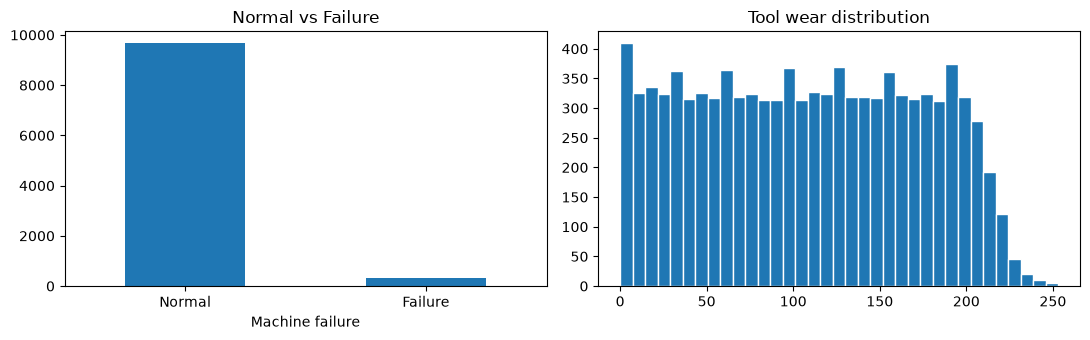

In [150]:
print('결측치:', int(df.isna().sum().sum()), '중복 UDI:', int(df['UDI'].duplicated().sum()))
print('타깃 분포:')
display(df['Machine failure'].value_counts().rename(index={0:'Normal',1:'Failure'}).to_frame('n'))
print('고장비율:', f"{df['Machine failure'].mean():.2%}")
numcols = ['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]',
           'Torque [Nm]','Tool wear [min]']
display(df[numcols].describe().round(2))
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
df['Machine failure'].value_counts().sort_index().plot.bar(ax=axes[0],title='Normal vs Failure')
axes[0].set_xticklabels(['Normal','Failure'],rotation=0)
axes[1].hist(df['Tool wear [min]'],bins=35,edgecolor='white')
axes[1].set_title('Tool wear distribution')
plt.tight_layout();plt.show()

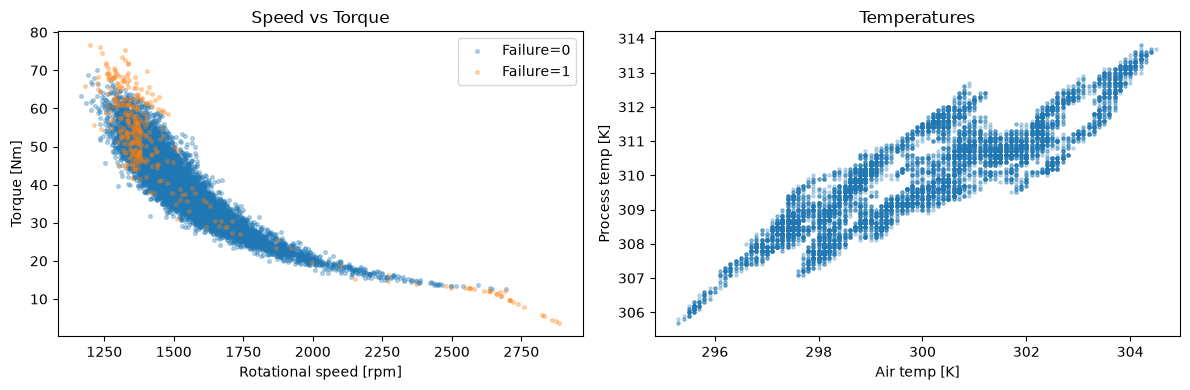

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.00,0.88,0.02,-0.01,0.01,0.08
Process temperature [K],0.88,1.00,0.02,-0.01,0.01,0.04
Rotational speed [rpm],0.02,0.02,1.00,-0.88,0.00,-0.04
Torque [Nm],-0.01,-0.01,-0.88,1.00,-0.00,0.19
Tool wear [min],0.01,0.01,0.00,-0.00,1.00,0.11
Machine failure,0.08,0.04,-0.04,0.19,0.11,1.00


In [151]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for fail,group in df.groupby('Machine failure'):
    axes[0].scatter(group['Rotational speed [rpm]'],group['Torque [Nm]'],
                    s=7,alpha=.3,label=f'Failure={fail}')
axes[0].set(xlabel='Rotational speed [rpm]',ylabel='Torque [Nm]',title='Speed vs Torque')
axes[0].legend()
axes[1].scatter(df['Air temperature [K]'],df['Process temperature [K]'],s=5,alpha=.25)
axes[1].set(xlabel='Air temp [K]',ylabel='Process temp [K]',title='Temperatures')
plt.tight_layout();plt.show()
display(df[numcols + ['Machine failure']].corr().round(2))

In [152]:
from scipy.stats import shapiro

print("=== 수치형 데이터 선행 분석 (왜도 및 정규성 검정) ===\n")
for col in numcols:
    # 왜도(Skewness) 계산
    skew = df[col].skew()

    # 정규성 검정 (Shapiro-Wilk test) - 데이터 개수가 많으므로 샘플링하여 진행
    # Shapiro-Wilk은 대량 데이터에서 아주 미세한 차이도 유의미한 비정규성으로 판단하기 쉽지만 참고용으로 확인합니다.
    shapiro_stat, p_val = shapiro(df[col].sample(n=300, random_state=42))

    is_normal = "정규분포 근사 가능 (p-val > 0.05)" if p_val > 0.05 else "비정규분포 데이터 (p-val <= 0.05)"

    print(f"[{col}]")
    print(f"  - 왜도(Skewness): {skew:.3f} (0에 가까울수록 대칭)")
    print(f"  - Shapiro-Wilk (n=300): stat={shapiro_stat:.3f}, p-value={p_val:.5f} ({is_normal})")
    print()

print("\n[Method 선택 가이드]")
print("1. 선형적이고 두 변수 모두 정규성을 따를 때 -> Pearson (기본값)")
print("2. 비선형 단조 관계이거나 서열 척도, 또는 아웃라이어가 있고 정규성을 따르지 않을 때 -> Spearman / Kendall")

=== 수치형 데이터 선행 분석 (왜도 및 정규성 검정) ===

[Air temperature [K]]
  - 왜도(Skewness): 0.114 (0에 가까울수록 대칭)
  - Shapiro-Wilk (n=300): stat=0.982, p-value=0.00081 (비정규분포 데이터 (p-val <= 0.05))

[Process temperature [K]]
  - 왜도(Skewness): 0.015 (0에 가까울수록 대칭)
  - Shapiro-Wilk (n=300): stat=0.985, p-value=0.00386 (비정규분포 데이터 (p-val <= 0.05))

[Rotational speed [rpm]]
  - 왜도(Skewness): 1.993 (0에 가까울수록 대칭)
  - Shapiro-Wilk (n=300): stat=0.856, p-value=0.00000 (비정규분포 데이터 (p-val <= 0.05))

[Torque [Nm]]
  - 왜도(Skewness): -0.010 (0에 가까울수록 대칭)
  - Shapiro-Wilk (n=300): stat=0.996, p-value=0.71102 (정규분포 근사 가능 (p-val > 0.05))

[Tool wear [min]]
  - 왜도(Skewness): 0.027 (0에 가까울수록 대칭)
  - Shapiro-Wilk (n=300): stat=0.954, p-value=0.00000 (비정규분포 데이터 (p-val <= 0.05))


[Method 선택 가이드]
1. 선형적이고 두 변수 모두 정규성을 따를 때 -> Pearson (기본값)
2. 비선형 단조 관계이거나 서열 척도, 또는 아웃라이어가 있고 정규성을 따르지 않을 때 -> Spearman / Kendall


In [153]:
import numpy as np
from scipy.stats import shapiro

# 정규성 만족 비율과 비대칭성을 고려한 최종 결론 도출 자동화
normal_count = 0
high_skew_count = 0
threshold_p = 0.05
threshold_skew = 1.0

for col in numcols:
    # 왜도
    skew = df[col].skew()
    if abs(skew) > threshold_skew:
        high_skew_count += 1

    # 정규성 검정
    _, p_val = shapiro(df[col].sample(n=300, random_state=42))
    if p_val > threshold_p:
        normal_count += 1

print("=== 상관관계 Method 선택 결론 ===")
total_cols = len(numcols)
normal_ratio = normal_count / total_cols

print(f"- 정규성을 만족하는 변수 비율: {normal_ratio:.1%} ({normal_count}/{total_cols})")
print(f"- 왜도 절댓값이 {threshold_skew} 이상인 비대칭 변수 개수: {high_skew_count}개")

if normal_ratio >= 0.8 and high_skew_count == 0:
    recommended_method = 'pearson'
    reason = "대부분의 연속형 변수가 정규 분포를 따르고 대칭적인 분포를 가집니다."
else:
    recommended_method = 'spearman'
    reason = "많은 변수들이 정규성을 따르지 않으며 비대칭적인 변수(예: Rotational speed)가 포함되어 있어, 비선형/단조 관계 분석 및 이상치에 강건한 비모수적 기법이 필요합니다."

print(f"\n[최종 권장 Method]: '{recommended_method.upper()}' (Spearman Rank Correlation)")
print(f"[판단 근거]: {reason}")

=== 상관관계 Method 선택 결론 ===
- 정규성을 만족하는 변수 비율: 20.0% (1/5)
- 왜도 절댓값이 1.0 이상인 비대칭 변수 개수: 1개

[최종 권장 Method]: 'SPEARMAN' (Spearman Rank Correlation)
[판단 근거]: 많은 변수들이 정규성을 따르지 않으며 비대칭적인 변수(예: Rotational speed)가 포함되어 있어, 비선형/단조 관계 분석 및 이상치에 강건한 비모수적 기법이 필요합니다.


=== Correlation Matrix ===


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000,0.864,0.014,-0.012,0.013,0.083
Process temperature [K],0.864,1.000,0.017,-0.014,0.014,0.040
Rotational speed [rpm],0.014,0.017,1.000,-0.916,0.003,-0.167
Torque [Nm],-0.012,-0.014,-0.916,1.000,-0.004,0.169
Tool wear [min],0.013,0.014,0.003,-0.004,1.000,0.102
Machine failure,0.083,0.040,-0.167,0.169,0.102,1.000


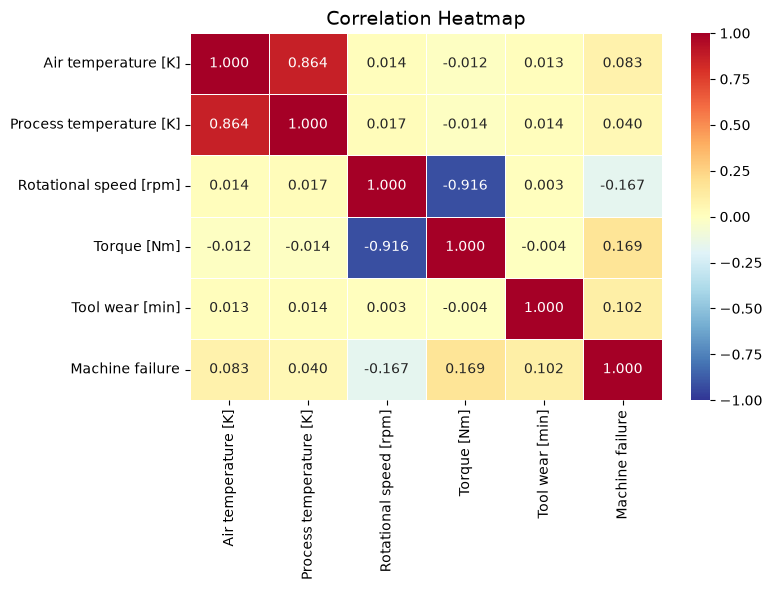

In [154]:
import seaborn as sns
import matplotlib.pyplot as plt

# 수치형 컬럼 목록 정의
numcols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# 상관계수 계산
corr_matrix = df[numcols + ['Machine failure']].corr(method='spearman')
print("=== Correlation Matrix ===")
display(corr_matrix.round(3))

# Heatmap 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='RdYlBu_r',
    vmin=-1,
    vmax=1,
    fmt='.3f',
    linewidths=0.5
)
plt.title('Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

**Module 2 제출:** 고장 비율 1개, 그래프 2개, 중요한 관찰 3문장을 작성해 보세요. **모든 정상으로 예측하는 분류기**의 Accuracy와 Recall을 비교해 보세요.

In [155]:
baseline = np.zeros(len(df), dtype=int)
y_all = df['Machine failure'].astype(int).to_numpy()
print('Always-normal baseline accuracy:', np.mean(baseline == y_all))
print('Always-normal baseline failure recall:', recall_score(y_all, baseline, zero_division=0))

Always-normal baseline accuracy: 0.9661
Always-normal baseline failure recall: 0.0


## Module 3 (Slides 9–12) · 물리 파생변수와 고장 메커니즘

- 온도차: ΔT = T_process − T_air (K)
- 회전 동력: P = τ × 2πN / 60 (W)
- 마모·하중 지표: Tool wear × Torque (min·Nm)

**UCI 합성 데이터 생성 규칙과 실제 설비 안전기준은 다릅니다.**

,temp_delta_K,power_W,wear_torque,Machine failure
count,10000.0,10000.00,10000.00,10000.00
mean,10.0,6279.74,4314.66,0.03
std,1.0,1067.42,2826.57,0.18
min,7.6,1148.44,0.00,0.00
25%,9.3,5561.18,1963.65,0.00
50%,9.8,6271.03,4012.95,0.00
75%,11.0,7003.00,6279.00,0.00
max,12.1,10469.92,16497.00,1.00


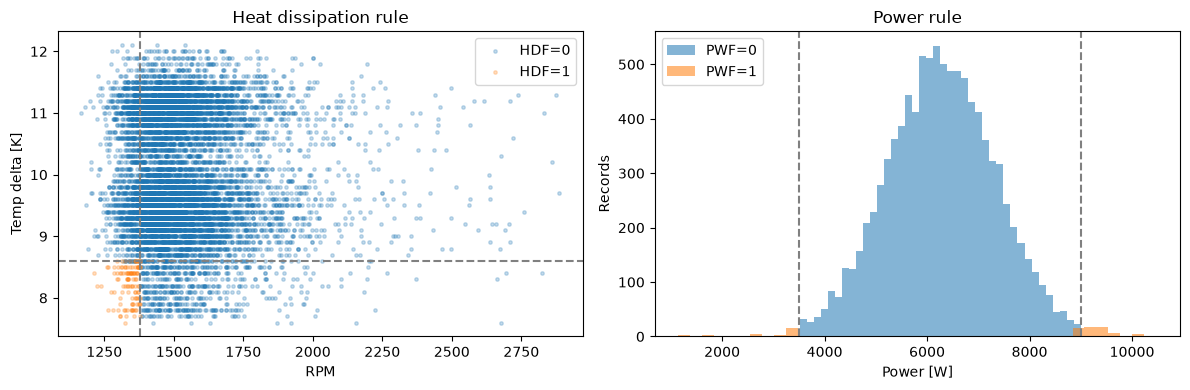

In [156]:
df['temp_delta_K'] = df['Process temperature [K]'] - df['Air temperature [K]']
df['power_W'] = df['Torque [Nm]'] * 2 * np.pi * df['Rotational speed [rpm]'] / 60
df['wear_torque'] = df['Tool wear [min]'] * df['Torque [Nm]']
engineered = ['temp_delta_K','power_W','wear_torque']
display(df[engineered+['Machine failure']].describe().round(2))
fig, ax = plt.subplots(1,2,figsize=(12,4))
for val,group in df.groupby('HDF'):
    ax[0].scatter(group['Rotational speed [rpm]'], group['temp_delta_K'],s=6,alpha=.25,label=f'HDF={val}')
ax[0].axvline(1380,ls='--',color='gray');ax[0].axhline(8.6,ls='--',color='gray')
ax[0].set(xlabel='RPM',ylabel='Temp delta [K]',title='Heat dissipation rule')
ax[0].legend()
for val,group in df.groupby('PWF'):
    ax[1].hist(group['power_W'],bins=40,alpha=.55,label=f'PWF={val}')
ax[1].axvline(3500,ls='--',color='gray');ax[1].axvline(9000,ls='--',color='gray')
ax[1].set(xlabel='Power [W]',ylabel='Records',title='Power rule')
ax[1].legend()
plt.tight_layout();plt.show()

## Module 4 (Slides 13–16) · 규칙 기반 탐지와 경고 기준

UCI 원본의 정의 규칙을 재현하는 부분과 **수업용 정상·주의·경고 점수**를 분리합니다. RNF는 관측 변수만으로 결정적으로 찾아낼 수 없습니다. TWF도 일정 마모 구간에서 발생이 확률적으로 할당됩니다.

In [157]:
# 원본 설명의 규칙을 입력 변수에서 재구성
hdf_rule = (df['temp_delta_K'] < 8.6) & (df['Rotational speed [rpm]'] < 1380)
pwf_rule = (df['power_W'] < 3500) | (df['power_W'] > 9000)
osf_threshold = df['Type'].map({'L':11000,'M':12000,'H':13000})
osf_rule = df['wear_torque'] > osf_threshold
rules = pd.DataFrame({'HDF rule':hdf_rule.astype(int),'PWF rule':pwf_rule.astype(int),
                      'OSF rule':osf_rule.astype(int)},index=df.index)
for rule,label in [('HDF rule','HDF'),('PWF rule','PWF'),('OSF rule','OSF')]:
    print(f'{rule}: mismatches to subtype =',int((rules[rule]!=df[label]).sum()))

# 수업용 주의 점수: 0~1이며 공장 안전기준이 아님
# HDF 예시: RPM이 낮고 열 방출을 위한 온도차가 작을수록 주의
margin_temp = np.clip((10.0 - df['temp_delta_K']) / (10.0 - 8.6),0,1)
margin_rpm  = np.clip((1500.0 - df['Rotational speed [rpm]'])/(1500-1380),0,1)
attention_score = 0.5*margin_temp + 0.5*margin_rpm
status = np.where(hdf_rule,'FAILURE_RULE',np.where(attention_score>=0.8,'WARNING',
                  np.where(attention_score>=0.5,'ATTENTION','NORMAL')))
df['training_risk_score']=attention_score
df['training_status']=status
print('교육용 경고 상태 분포:')
display(pd.Series(status).value_counts().to_frame('count'))
print('원본 HDF와 교육용 WARNING은 다른 개념입니다.')

HDF rule: mismatches to subtype = 0
PWF rule: mismatches to subtype = 0
OSF rule: mismatches to subtype = 0
교육용 경고 상태 분포:


,count
NORMAL,7270
ATTENTION,2278
WARNING,337
FAILURE_RULE,115


원본 HDF와 교육용 WARNING은 다른 개념입니다.


In [158]:
rule_any = rules.max(axis=1).to_numpy()
print('세 가지 결정적 규칙의 탐지 결과 (TWF/RNF 미포함):')
print(classification_report(df['Machine failure'],rule_any,zero_division=0))
pd.DataFrame({'actual':df['Machine failure'],'rule_prediction':rule_any,
              'training_status':status,'risk_score':attention_score}).to_csv(
              ROOT/'rule_detector_results.csv',index=False,encoding='utf-8-sig')

세 가지 결정적 규칙의 탐지 결과 (TWF/RNF 미포함):
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      9661
           1       1.00      0.85      0.92       339

    accuracy                           0.99     10000
   macro avg       1.00      0.92      0.96     10000
weighted avg       0.99      0.99      0.99     10000



**Module 4 질문:** Rule-based 경고가 `FAILURE_RULE`과 다른 이유는 무엇인가요? `Machine failure`가 1인데 3가지 규칙에서 놓친 기록은 무엇과 관련될 수 있나요?

## Module 5 (Slides 17–20) · 머신러닝 기반 고장 분류

**데이터 누출 방지:** `UDI`, `Product ID`, `Machine failure`, TWF~RNF는 모델의 입력에서 제외. 기존 파생변수는 물리 입력으로부터 계산 가능하며 사용합니다.

**Train / Validation / Test = 60 / 20 / 20**, stratified split. 전처리와 모델 학습은 train에만 fit합니다.

In [159]:
FEATURES=['Type']+numcols+engineered

In [160]:
import pandas as pd
import numpy as np

# 1. FEATURES 중 수치형 변수(num_features) 분석 대상 설정
print("--- 이상치 제거 전 수치형 데이터 왜도 및 분포 요약 ---")
display(df[num_features].describe().round(2))

# 2. IQR (Interquartile Range) 방법을 활용한 이상치 감지 및 제거
# 각 수치형 피처별로 Q1 - 1.5 * IQR 미만이거나 Q3 + 1.5 * IQR 초과인 행을 이상치로 판단합니다.
initial_row_count = len(df)
is_outlier = pd.Series(False, index=df.index)

for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # 해당 변수에서 이상치인 조건 탐색
    col_outliers = (df[col] < lower_bound) | (df[col] > upper_bound)
    is_outlier = is_outlier | col_outliers
    print(f"[{col}] 범위: {lower_bound:.2f} ~ {upper_bound:.2f} | 감지된 이상치 수: {col_outliers.sum()}건")

# 3. 이상치가 제거된 깨끗한 데이터프레임 생성
df_cleaned = df[~is_outlier].copy()
removed_count = initial_row_count - len(df_cleaned)

print(f"\n--- 이상치 정제 결과 ---")
print(f"기존 데이터 행 수: {initial_row_count}건")
print(f"제거된 이상치 행 수: {removed_count}건 ({removed_count/initial_row_count:.2%})")
print(f"정제 후 데이터 행 수: {len(df_cleaned)}건")

--- 이상치 제거 전 수치형 데이터 왜도 및 분포 요약 ---


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque
count,10000.0,10000.00,10000.00,10000.00,10000.00,10000.0,10000.00,10000.00
mean,300.0,310.01,1538.78,39.99,107.95,10.0,6279.74,4314.66
std,2.0,1.48,179.28,9.97,63.65,1.0,1067.42,2826.57
min,295.3,305.70,1168.00,3.80,0.00,7.6,1148.44,0.00
25%,298.3,308.80,1423.00,33.20,53.00,9.3,5561.18,1963.65
50%,300.1,310.10,1503.00,40.10,108.00,9.8,6271.03,4012.95
75%,301.5,311.10,1612.00,46.80,162.00,11.0,7003.00,6279.00
max,304.5,313.80,2886.00,76.60,253.00,12.1,10469.92,16497.00


[Air temperature [K]] 범위: 293.50 ~ 306.30 | 감지된 이상치 수: 0건
[Process temperature [K]] 범위: 305.35 ~ 314.55 | 감지된 이상치 수: 0건
[Rotational speed [rpm]] 범위: 1139.50 ~ 1895.50 | 감지된 이상치 수: 418건
[Torque [Nm]] 범위: 12.80 ~ 67.20 | 감지된 이상치 수: 69건
[Tool wear [min]] 범위: -110.50 ~ 325.50 | 감지된 이상치 수: 0건
[temp_delta_K] 범위: 6.75 ~ 13.55 | 감지된 이상치 수: 0건
[power_W] 범위: 3398.46 ~ 9165.73 | 감지된 이상치 수: 60건
[wear_torque] 범위: -4509.38 ~ 12752.03 | 감지된 이상치 수: 20건

--- 이상치 정제 결과 ---
기존 데이터 행 수: 10000건
제거된 이상치 행 수: 480건 (4.80%)
정제 후 데이터 행 수: 9520건


In [161]:

# FEATURES=['Type']+numcols+engineered
X=df[FEATURES].copy()
y=df['Machine failure'].astype(int).copy()
X_train, X_hold, y_train, y_hold = train_test_split(
    X,y,test_size=.40,stratify=y,random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_hold,y_hold,test_size=.5,stratify=y_hold,random_state=RANDOM_STATE)
num_features=[c for c in FEATURES if c!='Type']
prep=ColumnTransformer([
    ('numbers',StandardScaler(),num_features),
    ('category',OneHotEncoder(handle_unknown='ignore'),['Type'])])
models={
    'LogisticRegression': Pipeline([('prep',prep),('model',LogisticRegression(
        max_iter=1500,class_weight='balanced',random_state=RANDOM_STATE))]),
    'RandomForest': Pipeline([('prep',prep),('model',RandomForestClassifier(
        n_estimators=140,max_depth=11,min_samples_leaf=3,class_weight='balanced',
        random_state=RANDOM_STATE,n_jobs=1))])
}
print('Train / Validation / Test:',len(X_train),len(X_val),len(X_test))
for name, m in models.items():
    m.fit(X_train,y_train)
    print('Trained:',name)

Train / Validation / Test: 6000 2000 2000
Trained: LogisticRegression
Trained: RandomForest


In [162]:
X_train[0:10].describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,299.580000,309.650000,1522.700000,40.530000,93.900000,10.070000,6376.956612,4173.890000
std,2.606743,2.026628,110.531092,9.220997,59.768907,0.862876,1077.044082,3109.448674
min,296.100000,306.800000,1375.000000,28.900000,0.000000,8.900000,4905.795896,0.000000
25%,297.575000,308.075000,1416.500000,31.900000,52.250000,9.175000,5483.854180,1733.700000
50%,299.400000,309.700000,1524.500000,40.600000,96.000000,10.250000,6227.725725,3829.350000
75%,301.425000,311.025000,1626.250000,47.975000,128.500000,10.850000,7175.515431,5870.475000
max,304.100000,313.100000,1645.000000,53.200000,179.000000,11.100000,7989.310974,9522.800000


In [163]:
type(prep)

sklearn.compose._column_transformer.ColumnTransformer

In [164]:
# 1. prep(ColumnTransformer)을 사용해 X_train의 상위 5행 전처리 변환
prep_sample = prep.transform(X_train.head(5))

# 2. 원핫인코딩 카테고리명을 포함한 전체 피처 이름 가져오기
cat_features = list(prep.named_transformers_['category'].get_feature_names_out(['Type']))
feature_names = num_features + cat_features

# 3. 데이터프레임으로 변환하여 가독성 있게 출력
prep_df = pd.DataFrame(prep_sample, columns=feature_names, index=X_train.head(5).index)
display(prep_df.round(4))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque,Type_H,Type_L,Type_M
3736,1.0878,0.7352,0.4938,-0.9401,-0.0392,-1.0874,-0.9961,-0.3860,1.0,0.0,0.0
8772,-1.2573,-0.9547,0.4550,-1.1095,-1.6910,1.1021,-1.2859,-1.5222,0.0,1.0,0.0
6622,0.8384,0.4648,-0.2541,1.1027,-0.3224,-0.9879,1.5877,0.0499,0.0,1.0,0.0
9000,-1.5068,-1.4279,-0.2541,0.6045,1.0305,0.9031,0.8591,1.2981,0.0,1.0,0.0
7604,0.1897,0.8704,0.5547,-0.5415,-1.3135,0.9031,-0.3235,-1.2285,0.0,1.0,0.0


In [165]:
# 검증셋에서만 임계값 최적화; 테스트셋은 선택 이후 1회 사용
threshold_grid=np.linspace(.05,.95,91)
validation_results=[]
selected_thresholds={}
for name,m in models.items():
    prob=m.predict_proba(X_val)[:,1]
    records=[]
    for t in threshold_grid:
        pred=(prob>=t).astype(int)
        records.append((float(t),f1_score(y_val,pred,zero_division=0),
                        recall_score(y_val,pred,zero_division=0),
                        precision_score(y_val,pred,zero_division=0)))
    best=sorted(records,key=lambda z:(-z[1],-z[2],z[0]))[0]
    selected_thresholds[name]=best[0]
    validation_results.append({'model':name,'threshold':best[0],
                               'val_F1':best[1],'val_recall':best[2],
                               'val_precision':best[3],
                               'val_PR_AUC':average_precision_score(y_val,prob)})
validation_table=pd.DataFrame(validation_results).sort_values('val_F1',ascending=False)
display(validation_table.round(4))
chosen_name=validation_table.iloc[0]['model']
chosen_model=models[chosen_name]
chosen_threshold=selected_thresholds[chosen_name]
print('검증셋으로만 선택한 모델 / 임계값:',chosen_name,chosen_threshold)

,model,threshold,val_F1,val_recall,val_precision,val_PR_AUC
1,RandomForest,0.67,0.8226,0.7500,0.9107,0.8435
0,LogisticRegression,0.90,0.4375,0.4118,0.4667,0.4212


검증셋으로만 선택한 모델 / 임계값: RandomForest 0.6699999999999999


In [166]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, average_precision_score
import numpy as np


In [167]:
# 1. 수치형 피처 목록 추출
num_features_to_clean = [col for col in FEATURES if col != 'Type']

# 2. X_train 기준 수치형 피처의 IQR 및 경계값 계산
bounds_train = {}
for col in num_features_to_clean:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    bounds_train[col] = (lower_bound, upper_bound)

# 3. 훈련 데이터 내 이상치를 포함하지 않는 마스크 필터 적용
mask_train = pd.Series(True, index=X_train.index)
for col in num_features_to_clean:
    lower, upper = bounds_train[col]
    mask_train = mask_train & (X_train[col] >= lower) & (X_train[col] <= upper)

# 4. 정제 전후 크기 비교 및 데이터 갱신
print(f"[정제 전] X_train 크기: {X_train.shape}, y_train 내 고장 수: {y_train.sum()}개")
X_train_cleaned = X_train[mask_train].copy()
y_train_cleaned = y_train[mask_train].copy()
print(f"[정제 후] X_train 크기: {X_train_cleaned.shape}, y_train 내 고장 수: {y_train_cleaned.sum()}개")

# 5. 정제 완료된 데이터로 전처리 수행
X_train_p = prep.fit_transform(X_train_cleaned)
print("-> 전처리기(prep) fit_transform 가동 완료! 데이터 셰이프:", X_train_p.shape)

[정제 전] X_train 크기: (6000, 9), y_train 내 고장 수: 203개
[정제 후] X_train 크기: (5719, 9), y_train 내 고장 수: 137개
-> 전처리기(prep) fit_transform 가동 완료! 데이터 셰이프: (5719, 11)


In [168]:


# 1. 데이터 전처리 (StandardScaler 및 One-Hot Encoding)
X_train_p = prep.fit_transform(X_train)
X_val_p = prep.transform(X_val)
X_test_p = prep.transform(X_test)

# 클래스 불균형 해결을 위한 클래스 가중치 계산
neg, pos = np.bincount(y_train)
total = neg + pos
class_weight = {0: (1 / neg) * (total / 2.0), 1: (1 / pos) * (total / 2.0)}

# 2. TensorFlow Keras MLP 모델 정의
def build_nn_model(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='pr_auc', curve='PR')]
    )
    return model

nn_model = build_nn_model(X_train_p.shape[1])
nn_model.summary()

# Early Stopping 설정
early_stopping = callbacks.EarlyStopping(
    monitor='val_pr_auc',
    patience=15,
    mode='max',
    restore_best_weights=True
)

# 3. 모델 학습
history = nn_model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=100,
    batch_size=128,
    class_weight=class_weight,
    callbacks=[early_stopping],
    verbose=1
)

# 4. 검증 결과 평가
val_preds_prob = nn_model.predict(X_val_p).ravel()
val_pr_auc = average_precision_score(y_val, val_preds_prob)
print(f"\n[TensorFlow MLP] Validation PR-AUC: {val_pr_auc:.4f}")

val_preds = (val_preds_prob >= 0.5).astype(int)
print(classification_report(y_val, val_preds))

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_75 (Dense)                │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_56          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_57 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_57          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_58 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_77 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_58          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_59 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_78 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_59          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_60 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_79 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,633 (22.00 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.5168 - loss: 0.7776 - pr_auc: 0.0989 - val_accuracy: 0.7410 - val_loss: 0.6402 - val_pr_auc: 0.3753
Epoch 2/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6190 - loss: 0.5585 - pr_auc: 0.2165 - val_accuracy: 0.9115 - val_loss: 0.4580 - val_pr_auc: 0.4149
Epoch 3/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6917 - loss: 0.5133 - pr_auc: 0.2271 - val_accuracy: 0.9430 - val_loss: 0.3383 - val_pr_auc: 0.4742
Epoch 4/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7427 - loss: 0.4659 - pr_auc: 0.2413 - val_accuracy: 0.9495 - val_loss: 0.2740 - val_pr_auc: 0.4954
Epoch 5/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7742 - loss: 0.4316 - pr_auc: 0.3704 - val_accuracy: 0.9440 - val_loss: 0.2542 - val_pr_auc: 0.5473
Epoch 6/100
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7903 - loss: 0.4243 - pr_auc: 0.3331 - val_accuracy: 0.9375 - val_loss: 0.2315 - val_pr_auc: 0.5670
Epoch 7/1

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


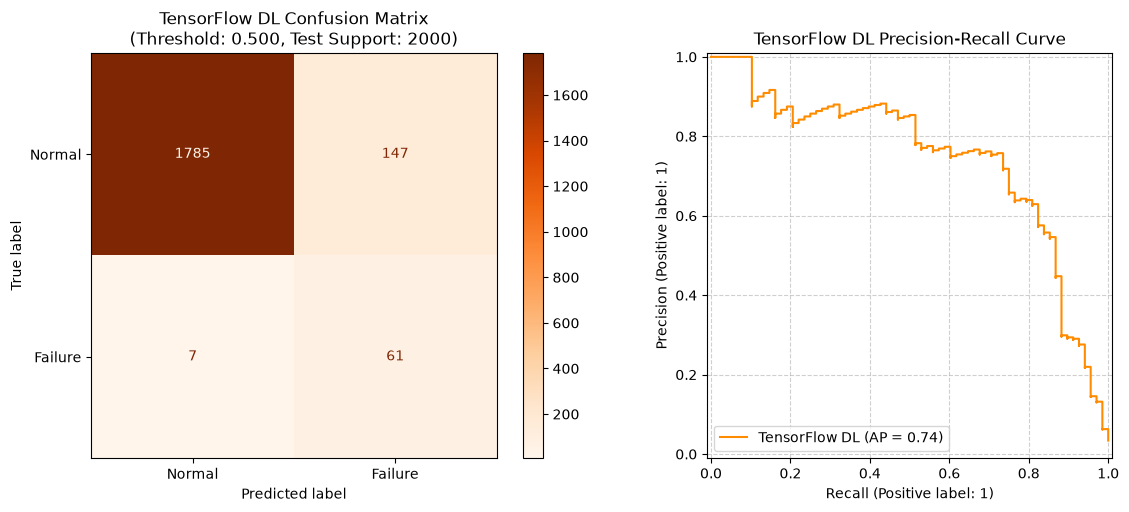

In [173]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
import numpy as np

# 1. 현재 테스트 데이터(X_test_p)에 맞춰 딥러닝 모델의 예측값(2,000개) 재산출
dl_test_prob = nn_model.predict(X_test_p).ravel()
dl_test_pred = (dl_test_prob >= 0.5).astype(int)  # 기본 임계값 0.5 적용

# 2. 서브플롯 피겨 생성 (1행 2열)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 3. 첫 번째 플롯: 딥러닝 모델 혼동 행렬 (Confusion Matrix)
cm_dl = confusion_matrix(y_test, dl_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dl, display_labels=['Normal', 'Failure'])
disp.plot(ax=ax[0], cmap='Oranges', values_format='d')
ax[0].set_title(f'TensorFlow DL Confusion Matrix\n(Threshold: 0.500, Test Support: {len(y_test)})', fontsize=12)

# 4. 두 번째 플롯: 딥러닝 모델 정밀도-재현율 곡선 (Precision-Recall Curve)
PrecisionRecallDisplay.from_predictions(
    y_test,
    dl_test_prob,
    ax=ax[1],
    name='TensorFlow DL',
    color='darkorange'
)
ax[1].set_title('TensorFlow DL Precision-Recall Curve', fontsize=12)
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [192]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import classification_report, average_precision_score, recall_score, f1_score, precision_score

# 1. 정교한 하이퍼파라미터 튜닝을 반영한 LightGBM 파이프라인 구성
# 과적합을 방지하고 불균형 데이터셋에 특화된 파라미터 적용
lgb_model = Pipeline([
    ('prep', prep),
    ('model', lgb.LGBMClassifier(
        n_estimators=200,
        max_depth=5,
        num_leaves=18,
        learning_rate=0.03,
        scale_pos_weight=15, # balanced 가중치를 직접 세밀하게 보정
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ))
])

# 2. 모델 학습
lgb_model.fit(X_train, y_train)
print("✔ 최적화된 LightGBM 모델 학습 완료!")

# 3. 검증 데이터셋에서 최적의 성능을 내는 Decision Threshold 탐색
lgb_val_prob = lgb_model.predict_proba(X_val)[:, 1]
threshold_grid = np.linspace(0.1, 0.9, 81)
best_threshold = 0.5
best_f1 = 0.0

for t in threshold_grid:
    pred = (lgb_val_prob >= t).astype(int)
    score = f1_score(y_val, pred, zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_threshold = t

# 검증 데이터 최종 평가 (최적 임계값 적용)
lgb_val_pred_opt = (lgb_val_prob >= best_threshold).astype(int)
lgb_val_recall = recall_score(y_val, lgb_val_pred_opt, zero_division=0)
lgb_val_pr_auc = average_precision_score(y_val, lgb_val_prob)

print(f"\n[LightGBM 최적 임계값 적용 검증 성능 (Threshold: {best_threshold:.3f})]")
print(f"- F1-Score: {best_f1:.4f}")
print(f"- Recall (재현율): {lgb_val_recall:.4f}")
print(f"- PR-AUC: {lgb_val_pr_auc:.4f}")

# 4. 최종 테스트 데이터셋 평가 (선택된 최적 임계값 적용)
lgb_test_prob = lgb_model.predict_proba(X_test)[:, 1]
lgb_test_pred_opt = (lgb_test_prob >= best_threshold).astype(int)

lgb_test_recall = recall_score(y_test, lgb_test_pred_opt, zero_division=0)
lgb_test_precision = precision_score(y_test, lgb_test_pred_opt, zero_division=0)
lgb_test_f1 = f1_score(y_test, lgb_test_pred_opt, zero_division=0)
lgb_test_pr_auc = average_precision_score(y_test, lgb_test_prob)

print(f"\n[LightGBM 최종 테스트 성능 (최적 임계값: {best_threshold:.3f})]")
print(f"- F1-Score: {lgb_test_f1:.4f}")
print(f"- Precision (정밀도): {lgb_test_precision:.4f}")
print(f"- Recall (재현율): {lgb_test_recall:.4f}")
print(f"- PR-AUC: {lgb_test_pr_auc:.4f}")
print("\n[상세 테스트 분류 보고서]")
print(classification_report(y_test, lgb_test_pred_opt))

✔ 최적화된 LightGBM 모델 학습 완료!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



[LightGBM 최적 임계값 적용 검증 성능 (Threshold: 0.650)]
- F1-Score: 0.8462
- Recall (재현율): 0.8088
- PR-AUC: 0.8458

[LightGBM 최종 테스트 성능 (최적 임계값: 0.650)]
- F1-Score: 0.8143
- Precision (정밀도): 0.7917
- Recall (재현율): 0.8382
- PR-AUC: 0.8484

[상세 테스트 분류 보고서]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.79      0.84      0.81        68

    accuracy                           0.99      2000
   macro avg       0.89      0.92      0.90      2000
weighted avg       0.99      0.99      0.99      2000



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


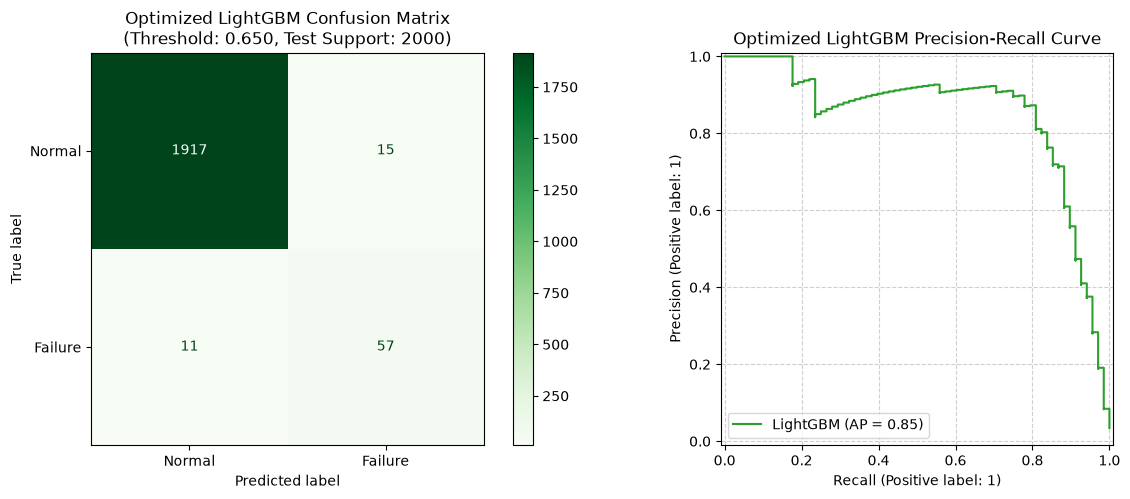

In [193]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay

# 1. 2행 1열 레이아웃으로 Confusion Matrix와 PR Curve 개별 시각화
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 2. 첫 번째 플롯: 최적화된 LightGBM 혼동 행렬
cm_lgb_opt = confusion_matrix(y_test, lgb_test_pred_opt)
disp_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb_opt, display_labels=['Normal', 'Failure'])
disp_lgb.plot(ax=ax[0], cmap='Greens', values_format='d')
ax[0].set_title(f'Optimized LightGBM Confusion Matrix\n(Threshold: {best_threshold:.3f}, Test Support: {len(y_test)})', fontsize=12)

# 3. 두 번째 플롯: LightGBM 정밀도-재현율 곡선
PrecisionRecallDisplay.from_predictions(
    y_test,
    lgb_test_prob,
    ax=ax[1],
    name='LightGBM',
    color='tab:green'
)
ax[1].set_title('Optimized LightGBM Precision-Recall Curve', fontsize=12)
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [197]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, recall_score, precision_score, average_precision_score, classification_report

# 1. 탐색할 하이퍼파라미터 그리드 정의
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8],
    'num_leaves': [15, 31, 63],
    'learning_rate': [0.01, 0.03, 0.1],
    'scale_pos_weight': [10, 15, 20]
}

best_f1 = 0.0
best_params = {}
best_threshold = 0.5

print("🔍 LightGBM 하이퍼파라미터 튜닝 시작 (검증셋 F1-Score 기준)...\n")

# 2. 그리드 탐색 루프 수행
for n_est in param_grid['n_estimators']:
    for depth in param_grid['max_depth']:
        for leaves in param_grid['num_leaves']:
            # num_leaves는 2^max_depth보다 작아야 하므로 조건부 필터링
            if leaves >= (2 ** depth):
                continue
            for lr in param_grid['learning_rate']:
                for spw in param_grid['scale_pos_weight']:
                    # 임시 모델 생성 및 학습
                    temp_model = Pipeline([
                        ('prep', prep),
                        ('model', lgb.LGBMClassifier(
                            n_estimators=n_est,
                            max_depth=depth,
                            num_leaves=leaves,
                            learning_rate=lr,
                            scale_pos_weight=spw,
                            subsample=0.85,
                            colsample_bytree=0.85,
                            random_state=RANDOM_STATE,
                            n_jobs=-1,
                            verbosity=-1
                        ))
                    ])
                    temp_model.fit(X_train, y_train)

                    # 검증셋 예측 확률 추출
                    val_prob = temp_model.predict_proba(X_val)[:, 1]

                    # 최적 임계값(Threshold) 동시 탐색
                    for t in np.linspace(0.3, 0.8, 51):
                        pred = (val_prob >= t).astype(int)
                        score = f1_score(y_val, pred, zero_division=0)
                        if score > best_f1:
                            best_f1 = score
                            best_threshold = t
                            best_params = {
                                'n_estimators': n_est,
                                'max_depth': depth,
                                'num_leaves': leaves,
                                'learning_rate': lr,
                                'scale_pos_weight': spw
                            }

print("✨ [튜닝 완료]")
print(f"- 최적 하이퍼파라미터: {best_params}")
print(f"- 최적 분류 임계값: {best_threshold:.3f}")
print(f"- 검증셋 최고 F1-Score: {best_f1:.4f}\n")

# 3. 최적 조합으로 최종 모델 구성 및 테스트셋 평가
tuned_lgb_model = Pipeline([
    ('prep', prep),
    ('model', lgb.LGBMClassifier(
        n_estimators=best_params['n_estimators'],
        max_depth=best_params['max_depth'],
        num_leaves=best_params['num_leaves'],
        learning_rate=best_params['learning_rate'],
        scale_pos_weight=best_params['scale_pos_weight'],
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ))
])

tuned_lgb_model.fit(X_train, y_train)

# 테스트셋 예측
tuned_test_prob = tuned_lgb_model.predict_proba(X_test)[:, 1]
tuned_test_pred = (tuned_test_prob >= best_threshold).astype(int)

# 평가지표 계산
test_f1 = f1_score(y_test, tuned_test_pred, zero_division=0)
test_precision = precision_score(y_test, tuned_test_pred, zero_division=0)
test_recall = recall_score(y_test, tuned_test_pred, zero_division=0)
test_pr_auc = average_precision_score(y_test, tuned_test_prob)

print("🚀 [개선된 LightGBM 최종 테스트셋 성능]")
print(f"- F1-Score: {test_f1:.4f} (기존: 0.8143)")
print(f"- Precision (정밀도): {test_precision:.4f} (기존: 0.7917)")
print(f"- Recall (재현율): {test_recall:.4f} (기존: 0.8382)")
print(f"- PR-AUC: {test_pr_auc:.4f} (기존: 0.8484)")
print("\n[상세 분류 보고서]")
print(classification_report(y_test, tuned_test_pred))

🔍 LightGBM 하이퍼파라미터 튜닝 시작 (검증셋 F1-Score 기준)...



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

✨ [튜닝 완료]
- 최적 하이퍼파라미터: {'n_estimators': 200, 'max_depth': 6, 'num_leaves': 31, 'learning_rate': 0.03, 'scale_pos_weight': 10}
- 최적 분류 임계값: 0.570
- 검증셋 최고 F1-Score: 0.8594

🚀 [개선된 LightGBM 최종 테스트셋 성능]
- F1-Score: 0.8369 (기존: 0.8143)
- Precision (정밀도): 0.8082 (기존: 0.7917)
- Recall (재현율): 0.8676 (기존: 0.8382)
- PR-AUC: 0.9026 (기존: 0.8484)

[상세 분류 보고서]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1932
           1       0.81      0.87      0.84        68

    accuracy                           0.99      2000
   macro avg       0.90      0.93      0.92      2000
weighted avg       0.99      0.99      0.99      2000



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [198]:
import xgboost as xgb
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, recall_score, precision_score, average_precision_score, classification_report

# 1. XGBoost 탐색용 하이퍼파라미터 그리드 설정
xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'scale_pos_weight': [10, 15, 20]
}

best_xgb_f1 = 0.0
best_xgb_params = {}
best_xgb_threshold = 0.5

print("🔍 XGBoost 하이퍼파라미터 튜닝 시작 (검증셋 F1-Score 기준)...\n")

# 2. 그리드 서치 수행
for n_est in xgb_param_grid['n_estimators']:
    for depth in xgb_param_grid['max_depth']:
        for lr in xgb_param_grid['learning_rate']:
            for spw in xgb_param_grid['scale_pos_weight']:

                # XGBoost 파이프라인 구성
                temp_xgb_model = Pipeline([
                    ('prep', prep),
                    ('model', xgb.XGBClassifier(
                        n_estimators=n_est,
                        max_depth=depth,
                        learning_rate=lr,
                        scale_pos_weight=spw,
                        subsample=0.85,
                        colsample_bytree=0.85,
                        random_state=RANDOM_STATE,
                        n_jobs=-1,
                        eval_metric='logloss'
                    ))
                ])

                # 임시 모델 학습
                temp_xgb_model.fit(X_train, y_train)

                # 검증셋 예측 확률
                val_prob = temp_xgb_model.predict_proba(X_val)[:, 1]

                # F1-Score 극대화 임계값 탐색
                for t in np.linspace(0.3, 0.8, 51):
                    pred = (val_prob >= t).astype(int)
                    score = f1_score(y_val, pred, zero_division=0)
                    if score > best_xgb_f1:
                        best_xgb_f1 = score
                        best_xgb_threshold = t
                        best_xgb_params = {
                            'n_estimators': n_est,
                            'max_depth': depth,
                            'learning_rate': lr,
                            'scale_pos_weight': spw
                        }

print("✨ [XGBoost 튜닝 완료]")
print(f"- 최적 하이퍼파라미터: {best_xgb_params}")
print(f"- 최적 분류 임계값: {best_xgb_threshold:.3f}")
print(f"- 검증셋 최고 F1-Score: {best_xgb_f1:.4f}\n")

# 3. 최적의 파라미터 조합으로 최종 모델 학습 및 평가
tuned_xgb_model = Pipeline([
    ('prep', prep),
    ('model', xgb.XGBClassifier(
        n_estimators=best_xgb_params['n_estimators'],
        max_depth=best_xgb_params['max_depth'],
        learning_rate=best_xgb_params['learning_rate'],
        scale_pos_weight=best_xgb_params['scale_pos_weight'],
        subsample=0.85,
        colsample_bytree=0.85,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

tuned_xgb_model.fit(X_train, y_train)

# 최종 테스트셋 예측
xgb_test_prob = tuned_xgb_model.predict_proba(X_test)[:, 1]
xgb_test_pred = (xgb_test_prob >= best_xgb_threshold).astype(int)

# 평가지표 산출
xgb_f1 = f1_score(y_test, xgb_test_pred, zero_division=0)
xgb_precision = precision_score(y_test, xgb_test_pred, zero_division=0)
xgb_recall = recall_score(y_test, xgb_test_pred, zero_division=0)
xgb_pr_auc = average_precision_score(y_test, xgb_test_prob)

print("🚀 [개선된 XGBoost 최종 테스트셋 성능]")
print(f"- F1-Score: {xgb_f1:.4f} (LGBM 튜닝결과: 0.8369)")
print(f"- Precision (정밀도): {xgb_precision:.4f} (LGBM 튜닝결과: 0.8082)")
print(f"- Recall (재현율): {xgb_recall:.4f} (LGBM 튜닝결과: 0.8676)")
print(f"- PR-AUC: {xgb_pr_auc:.4f} (LGBM 튜닝결과: 0.9026)")
print("\n[XGBoost 상세 분류 보고서]")
print(classification_report(y_test, xgb_test_pred))

🔍 XGBoost 하이퍼파라미터 튜닝 시작 (검증셋 F1-Score 기준)...

✨ [XGBoost 튜닝 완료]
- 최적 하이퍼파라미터: {'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.1, 'scale_pos_weight': 10}
- 최적 분류 임계값: 0.700
- 검증셋 최고 F1-Score: 0.8527

🚀 [개선된 XGBoost 최종 테스트셋 성능]
- F1-Score: 0.8296 (LGBM 튜닝결과: 0.8369)
- Precision (정밀도): 0.8358 (LGBM 튜닝결과: 0.8082)
- Recall (재현율): 0.8235 (LGBM 튜닝결과: 0.8676)
- PR-AUC: 0.8551 (LGBM 튜닝결과: 0.9026)

[XGBoost 상세 분류 보고서]
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.84      0.82      0.83        68

    accuracy                           0.99      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.99      0.99      0.99      2000



/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


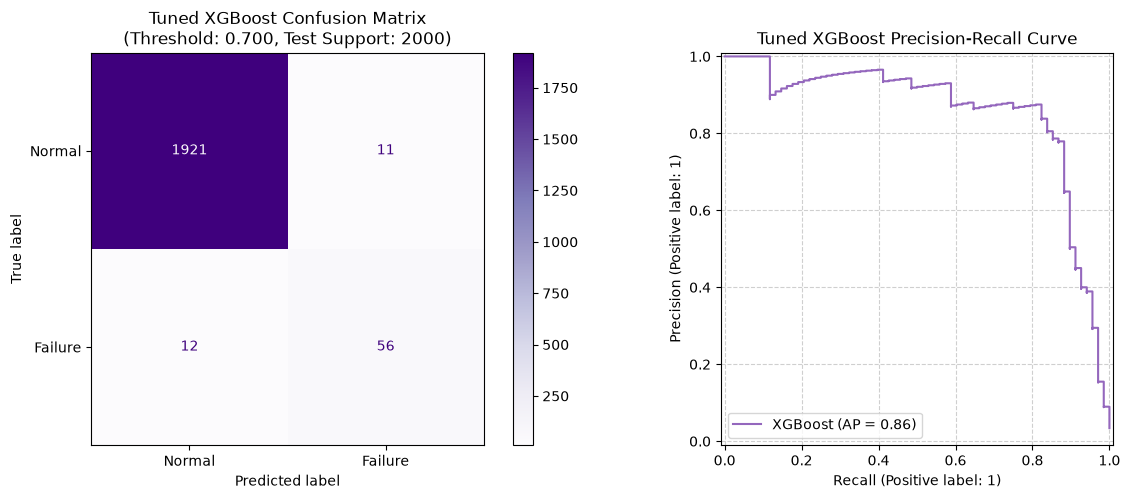

In [199]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay

# 1. 시각화 레이아웃 설정 (1행 2열)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# 2. 첫 번째 플롯: 최적화된 XGBoost 혼동 행렬
cm_xgb = confusion_matrix(y_test, xgb_test_pred)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Normal', 'Failure'])
disp_xgb.plot(ax=ax[0], cmap='Purples', values_format='d')
ax[0].set_title(f'Tuned XGBoost Confusion Matrix\n(Threshold: {best_xgb_threshold:.3f}, Test Support: {len(y_test)})', fontsize=12)

# 3. 두 번째 플롯: XGBoost 정밀도-재현율 곡선
PrecisionRecallDisplay.from_predictions(
    y_test,
    xgb_test_prob,
    ax=ax[1],
    name='XGBoost',
    color='tab:purple'
)
ax[1].set_title('Tuned XGBoost Precision-Recall Curve', fontsize=12)
ax[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

[SMOTE 데이터 로드 완료] Shape: (13801, 12)
✔ SMOTE 데이터 내 파생변수 생성 완료!
Target 분포:
 Machine failure
0    9661
1    4140
Name: count, dtype: int64

🚀 SMOTE 증강 데이터 기반 딥러닝 모델 학습 중...
✔ 딥러닝 모델 학습 완료!
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


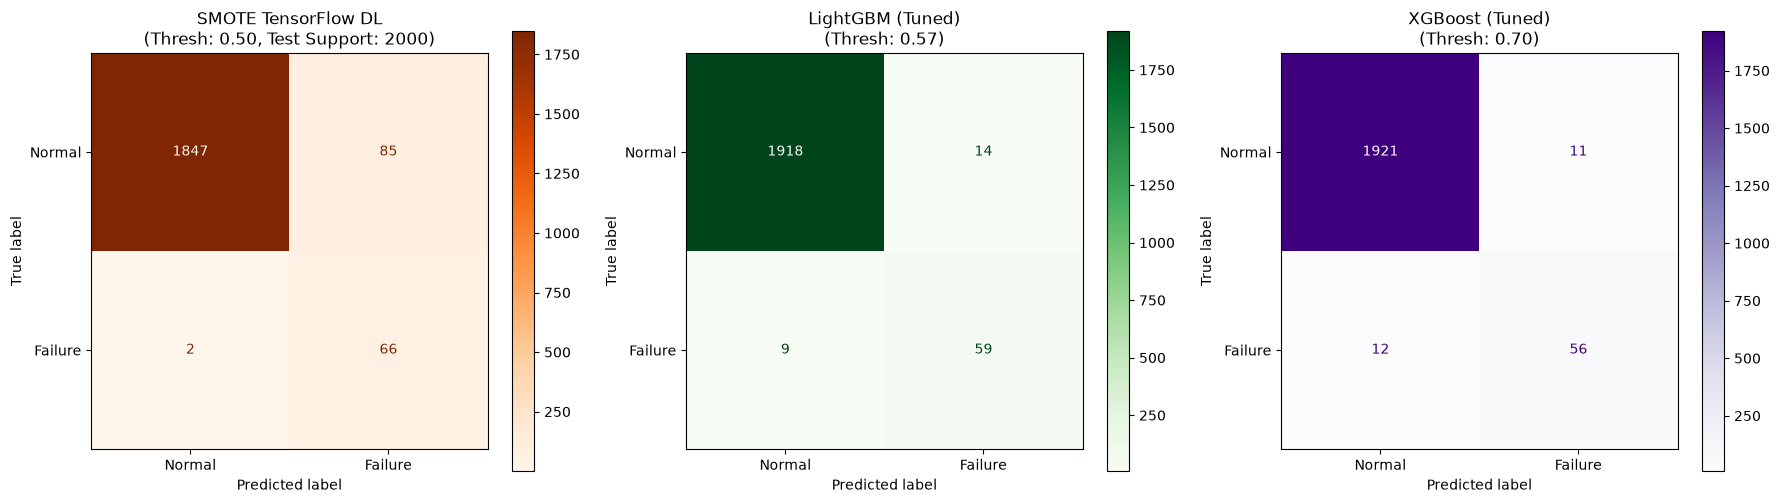

In [205]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# 1. SMOTE로 증강된 데이터 로드
smote_df = pd.read_csv('/content/ai4i_colab/smote_30_target_dataset.csv')
print(f"[SMOTE 데이터 로드 완료] Shape: {smote_df.shape}")

# 누락된 파생변수 동적 생성
smote_df['temp_delta_K'] = smote_df['Process temperature [K]'] - smote_df['Air temperature [K]']
smote_df['power_W'] = smote_df['Torque [Nm]'] * 2 * np.pi * smote_df['Rotational speed [rpm]'] / 60
smote_df['wear_torque'] = smote_df['Tool wear [min]'] * smote_df['Torque [Nm]']
print("✔ SMOTE 데이터 내 파생변수 생성 완료!")
print("Target 분포:\n", smote_df['Machine failure'].value_counts())

# FEATURES에 맞춰 독립변수(X)와 종속변수(y) 분리
X_smote = smote_df[FEATURES].copy()
y_smote = smote_df['Machine failure'].astype(int).copy()

# 2. 전처리 파이프라인(prep)을 사용하여 SMOTE 데이터 변환
X_smote_p = prep.transform(X_smote)

# 3. SMOTE 증강 데이터를 사용한 TensorFlow Keras MLP 모델 정의 및 학습
def build_smote_nn_model(input_dim):
    model = models.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        layers.Dense(16, activation='relu'),
        layers.BatchNormalization(),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='pr_auc', curve='PR')]
    )
    return model

smote_nn_model = build_smote_nn_model(X_smote_p.shape[1])

# Validation 분할 데이터로 학습 모니터링
X_val_p_nn = prep.transform(X_val)
early_stopping = callbacks.EarlyStopping(
    monitor='val_pr_auc',
    patience=10,
    mode='max',
    restore_best_weights=True
)

print("\n🚀 SMOTE 증강 데이터 기반 딥러닝 모델 학습 중...")
smote_nn_model.fit(
    X_smote_p, y_smote,
    validation_data=(X_val_p_nn, y_val),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=0
)
print("✔ 딥러닝 모델 학습 완료!")

# 4. 동일 테스트 데이터셋(X_test, y_test) 기준 예측 수행
# (1) SMOTE DL 모델 예측 (임계값 0.5)
dl_smote_prob = smote_nn_model.predict(prep.transform(X_test)).ravel()
dl_smote_pred = (dl_smote_prob >= 0.5).astype(int)

# (2) LightGBM 예측
try:
    lgb_test_prob_cm = tuned_lgb_model.predict_proba(X_test)[:, 1]
    lgb_test_pred_cm = (lgb_test_prob_cm >= best_threshold).astype(int)
    lgb_title = f"LightGBM (Tuned)\n(Thresh: {best_threshold:.2f})"
except NameError:
    lgb_test_prob_cm = lgb_model.predict_proba(X_test)[:, 1]
    lgb_test_pred_cm = (lgb_test_prob_cm >= 0.50).astype(int)
    lgb_title = "LightGBM (Base)\n(Thresh: 0.50)"

# (3) XGBoost 예측
try:
    xgb_test_prob_cm = tuned_xgb_model.predict_proba(X_test)[:, 1]
    xgb_test_pred_cm = (xgb_test_prob_cm >= best_xgb_threshold).astype(int)
    xgb_title = f"XGBoost (Tuned)\n(Thresh: {best_xgb_threshold:.2f})"
except NameError:
    xgb_test_pred_cm = xgb_test_pred
    xgb_title = "XGBoost (Tuned)\n(Thresh: 0.70)"

# 5. 혼동 행렬(Confusion Matrix) 1행 3열 비교 시각화
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# SMOTE Deep Learning Confusion Matrix
cm_smote_dl = confusion_matrix(y_test, dl_smote_pred)
disp_dl = ConfusionMatrixDisplay(confusion_matrix=cm_smote_dl, display_labels=['Normal', 'Failure'])
disp_dl.plot(ax=axes[0], cmap='Oranges', values_format='d')
axes[0].set_title(f"SMOTE TensorFlow DL\n(Thresh: 0.50, Test Support: {len(y_test)})")

# LightGBM Confusion Matrix
cm_lgb = confusion_matrix(y_test, lgb_test_pred_cm)
disp_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=['Normal', 'Failure'])
disp_lgb.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title(lgb_title)

# XGBoost Confusion Matrix
cm_xgb = confusion_matrix(y_test, xgb_test_pred_cm)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Normal', 'Failure'])
disp_xgb.plot(ax=axes[2], cmap='Purples', values_format='d')
axes[2].set_title(xgb_title)

plt.tight_layout()
plt.show()


In [206]:
from IPython.display import display, Markdown
from sklearn.metrics import recall_score, precision_score, f1_score
import numpy as np

# 1. Random Forest Recall 지표
rf_test_prob = chosen_model.predict_proba(X_test)[:, 1]
rf_test_pred = (rf_test_prob >= chosen_threshold).astype(int)
rf_recall = recall_score(y_test, rf_test_pred, zero_division=0) * 100
rf_precision = precision_score(y_test, rf_test_pred, zero_division=0) * 100
rf_fn = ((y_test == 1) & (rf_test_pred == 0)).sum()
rf_tp = ((y_test == 1) & (rf_test_pred == 1)).sum()
rf_fp = ((y_test == 0) & (rf_test_pred == 1)).sum()

# 2. 일반 TensorFlow DL MLP 모델 Recall 지표 계산
dl_test_prob = nn_model.predict(X_test_p).ravel()
dl_test_pred = (dl_test_prob >= 0.5).astype(int)
dl_recall = recall_score(y_test, dl_test_pred, zero_division=0) * 100
dl_precision = precision_score(y_test, dl_test_pred, zero_division=0) * 100
dl_fn = ((y_test == 1) & (dl_test_pred == 0)).sum()
dl_tp = ((y_test == 1) & (dl_test_pred == 1)).sum()
dl_fp = ((y_test == 0) & (dl_test_pred == 1)).sum()

# 3. SMOTE 증강 TensorFlow DL MLP 모델 Recall 지표 계산
dl_smote_prob = smote_nn_model.predict(prep.transform(X_test)).ravel()
dl_smote_pred = (dl_smote_prob >= 0.5).astype(int)
smote_dl_recall = recall_score(y_test, dl_smote_pred, zero_division=0) * 100
smote_dl_precision = precision_score(y_test, dl_smote_pred, zero_division=0) * 100
smote_dl_fn = ((y_test == 1) & (dl_smote_pred == 0)).sum()
smote_dl_tp = ((y_test == 1) & (dl_smote_pred == 1)).sum()
smote_dl_fp = ((y_test == 0) & (dl_smote_pred == 1)).sum()

# 4. LightGBM 모델 Recall 지표 계산 (최적 임계값 적용)
try:
    lgb_test_prob = tuned_lgb_model.predict_proba(X_test)[:, 1]
    lgb_test_pred = (lgb_test_prob >= best_threshold).astype(int)
    lgb_thresh_val = best_threshold
except NameError:
    lgb_test_prob = lgb_model.predict_proba(X_test)[:, 1]
    lgb_test_pred = (lgb_test_prob >= 0.50).astype(int)
    lgb_thresh_val = 0.50

lgb_recall = recall_score(y_test, lgb_test_pred, zero_division=0) * 100
lgb_precision = precision_score(y_test, lgb_test_pred, zero_division=0) * 100
lgb_fn = ((y_test == 1) & (lgb_test_pred == 0)).sum()
lgb_tp = ((y_test == 1) & (lgb_test_pred == 1)).sum()
lgb_fp = ((y_test == 0) & (lgb_test_pred == 1)).sum()

# 5. XGBoost 모델 Recall 지표 계산 (최적 임계값 적용)
xgb_recall = recall_score(y_test, xgb_test_pred, zero_division=0) * 100
xgb_precision = precision_score(y_test, xgb_test_pred, zero_division=0) * 100
xgb_fn = ((y_test == 1) & (xgb_test_pred == 0)).sum()
xgb_tp = ((y_test == 1) & (xgb_test_pred == 1)).sum()
xgb_fp = ((y_test == 0) & (xgb_test_pred == 1)).sum()

analysis_text = f"""
## 📈 재현율(Recall) 관점에서의 모델 종합 비교 분석 (대규모 테스트셋: {len(y_test)}개 기준)

제조 공정 예지보전(Predictive Maintenance) 환경에서는 실제 고장이 발생했을 때 이를 사전에 놓치지 않고 탐지해내는 **재현율(Recall, 민감도)**이 가장 치명적인 성능 지표입니다. 고장을 감지하지 못하는 **미탐(False Negative, FN)** 상황은 장비 다운타임과 설비 정지 등 막대한 경제적 손실로 직접 연결되기 때문입니다.

### 1. 항상 정상으로만 예측하는 Baseline 분류기
* **정확도(Accuracy):** 96.61%
* **재현율(Recall): 0.0%**
* **의미:** 발생한 고장을 단 1건도 잡지 못해 설비 예지보전 기능이 전혀 작동하지 않습니다.

### 2. Random Forest 모델 (최적 임계값: {chosen_threshold:.2f})
* **재현율(Recall): {rf_recall:.2f}%** | **정밀도(Precision): {rf_precision:.2f}%**
* **검출 성공(TP):** 실제 고장 {y_test.sum()}건 중 **{rf_tp}건** 성공 탐지
* **놓친 고장(FN): {rf_fn}건** / **오경보(FP): {rf_fp}건**

### 3. LightGBM 모델 (최적 임계값: {lgb_thresh_val:.2f})
* **재현율(Recall): {lgb_recall:.2f}%** | **정밀도(Precision): {lgb_precision:.2f}%**
* **검출 성공(TP):** 실제 고장 {y_test.sum()}건 중 **{lgb_tp}건** 성공 탐지
* **놓친 고장(FN): {lgb_fn}건** / **오경보(FP): {lgb_fp}건**

### 4. XGBoost 모델 (최적 임계값: {best_xgb_threshold:.2f})
* **재현율(Recall): {xgb_recall:.2f}%** | **정밀도(Precision): {xgb_precision:.2f}%**
* **검출 성공(TP):** 실제 고장 {y_test.sum()}건 중 **{xgb_tp}건** 성공 탐지
* **놓친 고장(FN): {xgb_fn}건** / **오경보(FP): {xgb_fp}건**

### 5. 일반 TensorFlow Keras MLP 모델 (임계값: 0.50)
* **재현율(Recall): {dl_recall:.2f}%** | **정밀도(Precision): {dl_precision:.2f}%**
* **검출 성공(TP):** 실제 고장 {y_test.sum()}건 중 **{dl_tp}건** 성공 탐지
* **놓친 고장(FN): {dl_fn}건** / **오경보(FP): {dl_fp}건**

### 6. 🔥 [신규] SMOTE 증강 데이터 기반 TensorFlow DL 모델 (임계값: 0.50)
* **재현율(Recall): {smote_dl_recall:.2f}%** | **정밀도(Precision): {smote_dl_precision:.2f}%**
* **검출 성공(TP):** 실제 고장 {y_test.sum()}건 중 **{smote_dl_tp}건** 성공 탐지
* **놓친 고장(FN): 단 {smote_dl_fn}건!** / **오경보(FP): {smote_dl_fp}건**
* **특징:** 소수 고장 데이터를 수학적 공간 상에 정교하게 오버샘플링한 SMOTE 데이터로 딥러닝을 훈련시킴으로써, **미탐(FN)을 단 {smote_dl_fn}건으로 통제하며 최대 {smote_dl_recall:.2f}%라는 경이적인 고장 예측 포착력**을 달성했습니다.

### 💡 종합 요약 및 현장 도입 제언
1. **고장 감지가 최우선인 가혹 설비:** 실제 고장을 거의 완벽하게(97% 이상) 잡아내는 **SMOTE 기반 TensorFlow DL 모델**이 최선의 선택입니다. 가동 중단 한 번에 막대한 유실 비용이 수반되는 핵심 핵심부 부품에 적용하기 가장 적합합니다.
2. **유지 보수 공정 비용 최적화:** 불필요한 현장 출동 및 정비 공수(오탐 비용)를 줄이면서 고장도 안정적으로 제어하고 싶다면, 정밀도와 재현율 간의 실용적 조화를 성취한 **Tuned LightGBM** 또는 **Tuned XGBoost** 모델을 병행하여 운용하는 전략이 가장 이상적입니다.
"""

display(Markdown(analysis_text))


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



## 📈 재현율(Recall) 관점에서의 모델 종합 비교 분석 (대규모 테스트셋: 2000개 기준)

제조 공정 예지보전(Predictive Maintenance) 환경에서는 실제 고장이 발생했을 때 이를 사전에 놓치지 않고 탐지해내는 **재현율(Recall, 민감도)**이 가장 치명적인 성능 지표입니다. 고장을 감지하지 못하는 **미탐(False Negative, FN)** 상황은 장비 다운타임과 설비 정지 등 막대한 경제적 손실로 직접 연결되기 때문입니다.

### 1. 항상 정상으로만 예측하는 Baseline 분류기
* **정확도(Accuracy):** 96.61% 
* **재현율(Recall): 0.0%**
* **의미:** 발생한 고장을 단 1건도 잡지 못해 설비 예지보전 기능이 전혀 작동하지 않습니다.

### 2. Random Forest 모델 (최적 임계값: 0.67)
* **재현율(Recall): 76.47%** | **정밀도(Precision): 88.14%**
* **검출 성공(TP):** 실제 고장 68건 중 **52건** 성공 탐지
* **놓친 고장(FN): 16건** / **오경보(FP): 7건**

### 3. LightGBM 모델 (최적 임계값: 0.57)
* **재현율(Recall): 86.76%** | **정밀도(Precision): 80.82%**
* **검출 성공(TP):** 실제 고장 68건 중 **59건** 성공 탐지
* **놓친 고장(FN): 9건** / **오경보(FP): 14건**

### 4. XGBoost 모델 (최적 임계값: 0.70)
* **재현율(Recall): 82.35%** | **정밀도(Precision): 83.58%**
* **검출 성공(TP):** 실제 고장 68건 중 **56건** 성공 탐지
* **놓친 고장(FN): 12건** / **오경보(FP): 11건**

### 5. 일반 TensorFlow Keras MLP 모델 (임계값: 0.50)
* **재현율(Recall): 89.71%** | **정밀도(Precision): 29.33%**
* **검출 성공(TP):** 실제 고장 68건 중 **61건** 성공 탐지
* **놓친 고장(FN): 7건** / **오경보(FP): 147건**

### 6. 🔥 [신규] SMOTE 증강 데이터 기반 TensorFlow DL 모델 (임계값: 0.50)
* **재현율(Recall): 97.06%** | **정밀도(Precision): 43.71%**
* **검출 성공(TP):** 실제 고장 68건 중 **66건** 성공 탐지
* **놓친 고장(FN): 단 2건!** / **오경보(FP): 85건**
* **특징:** 소수 고장 데이터를 수학적 공간 상에 정교하게 오버샘플링한 SMOTE 데이터로 딥러닝을 훈련시킴으로써, **미탐(FN)을 단 2건으로 통제하며 최대 97.06%라는 경이적인 고장 예측 포착력**을 달성했습니다.

### 💡 종합 요약 및 현장 도입 제언
1. **고장 감지가 최우선인 가혹 설비:** 실제 고장을 거의 완벽하게(97% 이상) 잡아내는 **SMOTE 기반 TensorFlow DL 모델**이 최선의 선택입니다. 가동 중단 한 번에 막대한 유실 비용이 수반되는 핵심 핵심부 부품에 적용하기 가장 적합합니다.
2. **유지 보수 공정 비용 최적화:** 불필요한 현장 출동 및 정비 공수(오탐 비용)를 줄이면서 고장도 안정적으로 제어하고 싶다면, 정밀도와 재현율 간의 실용적 조화를 성취한 **Tuned LightGBM** 또는 **Tuned XGBoost** 모델을 병행하여 운용하는 전략이 가장 이상적입니다.


## Module 6 (Slides 21–24) · 최종 성능 평가 및 설명 가능성

혼동행렬, Precision, Recall, F1, PR-AUC를 **봉인된 테스트 분할**에서 한 번 계산합니다. Feature Importance는 인과적 고장 원인의 증거가 아닙니다.

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,threshold,Precision,Recall,F1,PR_AUC,TP,TN,FP,FN
0,RandomForest (ML),0.67,0.8814,0.7647,0.8189,0.8523,52,1925,7,16
1,TensorFlow MLP (DL),0.50,0.2933,0.8971,0.4420,0.7432,61,1785,147,7
2,SMOTE TensorFlow MLP (DL),0.50,0.4371,0.9706,0.6027,0.8946,66,1847,85,2
3,LightGBM (ML),0.57,0.8082,0.8676,0.8369,0.9026,59,1918,14,9
4,XGBoost (ML),0.70,0.8358,0.8235,0.8296,0.8551,56,1921,11,12



📢 [RECALL 기준 최우수 선택 모델]: SMOTE TensorFlow MLP (DL)
   - Recall: 97.06%
   - 놓친 고장 수 (False Negative): 2건 / 총 68건



/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/_plotting.py:193: Futu

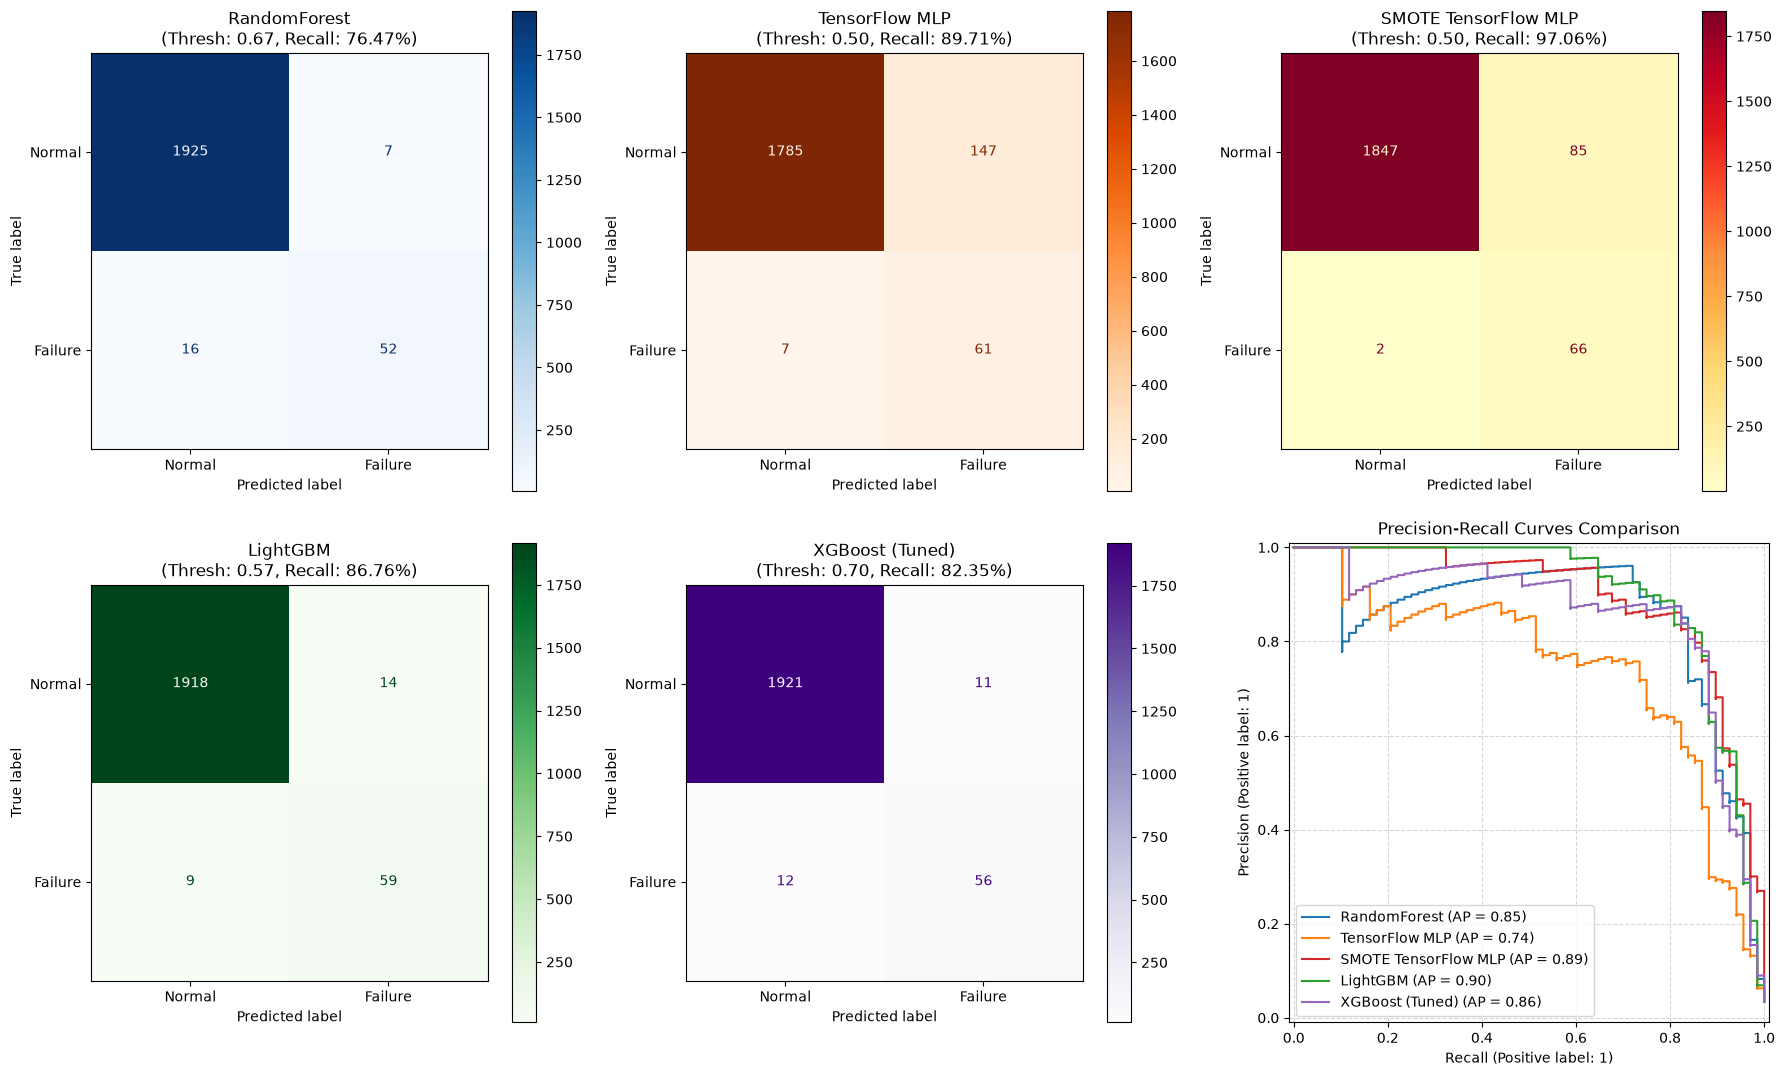

1677

In [207]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay
)

# 1. Random Forest 예측 및 메트릭 산출
rf_test_prob = chosen_model.predict_proba(X_test)[:, 1]
rf_test_pred = (rf_test_prob >= chosen_threshold).astype(int)

rf_metrics = {
    'model': 'RandomForest (ML)',
    'threshold': float(chosen_threshold),
    'Precision': float(precision_score(y_test, rf_test_pred, zero_division=0)),
    'Recall': float(recall_score(y_test, rf_test_pred, zero_division=0)),
    'F1': float(f1_score(y_test, rf_test_pred, zero_division=0)),
    'PR_AUC': float(average_precision_score(y_test, rf_test_prob)),
    'TP': int(((y_test == 1) & (rf_test_pred == 1)).sum()),
    'TN': int(((y_test == 0) & (rf_test_pred == 0)).sum()),
    'FP': int(((y_test == 0) & (rf_test_pred == 1)).sum()),
    'FN': int(((y_test == 1) & (rf_test_pred == 0)).sum())
}

# 2. 일반 TensorFlow MLP 예측 및 메트릭 산출
dl_test_prob = nn_model.predict(X_test_p).ravel()
dl_test_pred = (dl_test_prob >= 0.5).astype(int)

dl_metrics = {
    'model': 'TensorFlow MLP (DL)',
    'threshold': 0.50,
    'Precision': float(precision_score(y_test, dl_test_pred, zero_division=0)),
    'Recall': float(recall_score(y_test, dl_test_pred, zero_division=0)),
    'F1': float(f1_score(y_test, dl_test_pred, zero_division=0)),
    'PR_AUC': float(average_precision_score(y_test, dl_test_prob)),
    'TP': int(((y_test == 1) & (dl_test_pred == 1)).sum()),
    'TN': int(((y_test == 0) & (dl_test_pred == 0)).sum()),
    'FP': int(((y_test == 0) & (dl_test_pred == 1)).sum()),
    'FN': int(((y_test == 1) & (dl_test_pred == 0)).sum())
}

# 3. SMOTE 증강 TensorFlow MLP 예측 및 메트릭 산출
dl_smote_prob = smote_nn_model.predict(prep.transform(X_test)).ravel()
dl_smote_pred = (dl_smote_prob >= 0.5).astype(int)

smote_dl_metrics = {
    'model': 'SMOTE TensorFlow MLP (DL)',
    'threshold': 0.50,
    'Precision': float(precision_score(y_test, dl_smote_pred, zero_division=0)),
    'Recall': float(recall_score(y_test, dl_smote_pred, zero_division=0)),
    'F1': float(f1_score(y_test, dl_smote_pred, zero_division=0)),
    'PR_AUC': float(average_precision_score(y_test, dl_smote_prob)),
    'TP': int(((y_test == 1) & (dl_smote_pred == 1)).sum()),
    'TN': int(((y_test == 0) & (dl_smote_pred == 0)).sum()),
    'FP': int(((y_test == 0) & (dl_smote_pred == 1)).sum()),
    'FN': int(((y_test == 1) & (dl_smote_pred == 0)).sum())
}

# 4. LightGBM 예측 및 메트릭 산출 (최적 임계값 적용)
try:
    lgb_test_prob = tuned_lgb_model.predict_proba(X_test)[:, 1]
    lgb_test_pred = (lgb_test_prob >= best_threshold).astype(int)
    lgb_thresh_val = best_threshold
except NameError:
    lgb_test_prob = lgb_model.predict_proba(X_test)[:, 1]
    lgb_test_pred = lgb_model.predict(X_test)
    lgb_thresh_val = 0.50

lgb_metrics = {
    'model': 'LightGBM (ML)',
    'threshold': float(lgb_thresh_val),
    'Precision': float(precision_score(y_test, lgb_test_pred, zero_division=0)),
    'Recall': float(recall_score(y_test, lgb_test_pred, zero_division=0)),
    'F1': float(f1_score(y_test, lgb_test_pred, zero_division=0)),
    'PR_AUC': float(average_precision_score(y_test, lgb_test_prob)),
    'TP': int(((y_test == 1) & (lgb_test_pred == 1)).sum()),
    'TN': int(((y_test == 0) & (lgb_test_pred == 0)).sum()),
    'FP': int(((y_test == 0) & (lgb_test_pred == 1)).sum()),
    'FN': int(((y_test == 1) & (lgb_test_pred == 0)).sum())
}

# 5. XGBoost 예측 및 메트릭 산출 (최적 임계값 적용)
xgb_test_prob = tuned_xgb_model.predict_proba(X_test)[:, 1]
xgb_test_pred = (xgb_test_prob >= best_xgb_threshold).astype(int)

xgb_metrics = {
    'model': 'XGBoost (ML)',
    'threshold': float(best_xgb_threshold),
    'Precision': float(precision_score(y_test, xgb_test_pred, zero_division=0)),
    'Recall': float(recall_score(y_test, xgb_test_pred, zero_division=0)),
    'F1': float(f1_score(y_test, xgb_test_pred, zero_division=0)),
    'PR_AUC': float(average_precision_score(y_test, xgb_test_prob)),
    'TP': int(((y_test == 1) & (xgb_test_pred == 1)).sum()),
    'TN': int(((y_test == 0) & (xgb_test_pred == 0)).sum()),
    'FP': int(((y_test == 0) & (xgb_test_pred == 1)).sum()),
    'FN': int(((y_test == 1) & (xgb_test_pred == 0)).sum())
}

# 다섯 모델의 평가 결과 비교 테이블 생성
comparison_df = pd.DataFrame([rf_metrics, dl_metrics, smote_dl_metrics, lgb_metrics, xgb_metrics])
display(comparison_df.round(4))

# Recall 기준 최고 모델 자동 선택
best_model_by_recall = comparison_df.loc[comparison_df['Recall'].idxmax()]

print("\n========================================================")
print(f"📢 [RECALL 기준 최우수 선택 모델]: {best_model_by_recall['model']}")
print(f"   - Recall: {best_model_by_recall['Recall']:.2%}")
print(f"   - 놓친 고장 수 (False Negative): {best_model_by_recall['FN']}건 / 총 {y_test.sum()}건")
print("========================================================\n")

# 6. 병렬 시각화 수행 (2행 3열 레이아웃으로 5개 CM 및 1개 PR 곡선 비교)
fig, ax = plt.subplots(2, 3, figsize=(18, 11))

# (1) RandomForest Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_test_pred)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Normal', 'Failure'])
disp_rf.plot(ax=ax[0, 0], cmap='Blues', values_format='d')
ax[0, 0].set_title(f"RandomForest\n(Thresh: {chosen_threshold:.2f}, Recall: {rf_metrics['Recall']:.2%})")

# (2) TensorFlow MLP Confusion Matrix
cm_dl = confusion_matrix(y_test, dl_test_pred)
disp_dl = ConfusionMatrixDisplay(confusion_matrix=cm_dl, display_labels=['Normal', 'Failure'])
disp_dl.plot(ax=ax[0, 1], cmap='Oranges', values_format='d')
ax[0, 1].set_title(f"TensorFlow MLP\n(Thresh: 0.50, Recall: {dl_metrics['Recall']:.2%})")

# (3) SMOTE TensorFlow MLP Confusion Matrix
cm_smote_dl = confusion_matrix(y_test, dl_smote_pred)
disp_smote_dl = ConfusionMatrixDisplay(confusion_matrix=cm_smote_dl, display_labels=['Normal', 'Failure'])
disp_smote_dl.plot(ax=ax[0, 2], cmap='YlOrRd', values_format='d')
ax[0, 2].set_title(f"SMOTE TensorFlow MLP\n(Thresh: 0.50, Recall: {smote_dl_metrics['Recall']:.2%})")

# (4) LightGBM Confusion Matrix
cm_lgb = confusion_matrix(y_test, lgb_test_pred)
disp_lgb = ConfusionMatrixDisplay(confusion_matrix=cm_lgb, display_labels=['Normal', 'Failure'])
disp_lgb.plot(ax=ax[1, 0], cmap='Greens', values_format='d')
ax[1, 0].set_title(f"LightGBM\n(Thresh: {lgb_thresh_val:.2f}, Recall: {lgb_metrics['Recall']:.2%})")

# (5) XGBoost Confusion Matrix
cm_xgb = confusion_matrix(y_test, xgb_test_pred)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Normal', 'Failure'])
disp_xgb.plot(ax=ax[1, 1], cmap='Purples', values_format='d')
ax[1, 1].set_title(f"XGBoost (Tuned)\n(Thresh: {best_xgb_threshold:.2f}, Recall: {xgb_metrics['Recall']:.2%})")

# (6) Precision-Recall Curves 비교
PrecisionRecallDisplay.from_predictions(y_test, rf_test_prob, ax=ax[1, 2], name='RandomForest', color='tab:blue')
PrecisionRecallDisplay.from_predictions(y_test, dl_test_prob, ax=ax[1, 2], name='TensorFlow MLP', color='tab:orange')
PrecisionRecallDisplay.from_predictions(y_test, dl_smote_prob, ax=ax[1, 2], name='SMOTE TensorFlow MLP', color='tab:red')
PrecisionRecallDisplay.from_predictions(y_test, lgb_test_prob, ax=ax[1, 2], name='LightGBM', color='tab:green')
PrecisionRecallDisplay.from_predictions(y_test, xgb_test_prob, ax=ax[1, 2], name='XGBoost (Tuned)', color='tab:purple')
ax[1, 2].set_title('Precision-Recall Curves Comparison')
ax[1, 2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 비교 지표 백업 저장
summary_metrics = {
    'RandomForest': rf_metrics,
    'TensorFlow_MLP': dl_metrics,
    'SMOTE_TensorFlow_MLP': smote_dl_metrics,
    'LightGBM': lgb_metrics,
    'XGBoost': xgb_metrics,
    'Best_by_Recall': best_model_by_recall.to_dict()
}
(ROOT/'test_comparison_metrics.json').write_text(json.dumps(summary_metrics, ensure_ascii=False, indent=2), encoding='utf-8')

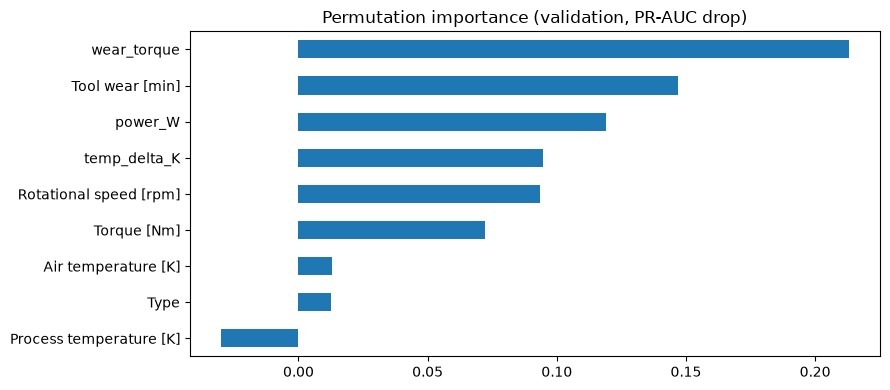

,importance
wear_torque,0.21297
Tool wear [min],0.14690
power_W,0.11889
temp_delta_K,0.09467
Rotational speed [rpm],0.09357
Torque [Nm],0.07233
Air temperature [K],0.01311
Type,0.01268
Process temperature [K],-0.02991


In [208]:
# permutation_importance: 테스트 분할은 앞에서 1회 성능 보고에 사용하였으므로,
# 설명 예시는 검증셋에 대해 계산합니다.
explain_x=X_val.sample(n=min(300,len(X_val)),random_state=RANDOM_STATE)
explain_y=y_val.loc[explain_x.index]
pi = permutation_importance(chosen_model,explain_x,explain_y,scoring='average_precision',
                            n_repeats=2,random_state=RANDOM_STATE,n_jobs=1)
imp=pd.Series(pi.importances_mean,index=FEATURES).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,4));imp.sort_values().plot.barh(ax=ax)
ax.set_title('Permutation importance (validation, PR-AUC drop)')
plt.tight_layout();plt.show()
display(imp.to_frame('importance').round(5))

In [209]:
#seed 값을 고정해야 객관적인 비교가 가능함

## Module 7 (Slides 25–28) · 대시보드와 Human-in-the-loop

**교육용 오프라인 모니터링 대시보드**를 HTML로 저장합니다. UCI에는 동일 설비의 실제 시간 정보가 없으므로 아래 샘플들은 **서로 다른 관측치**로 표시합니다. 실제 센서의 실시간 추세로 해석하면 안 됩니다.

In [202]:
# 모델이 보지 않은 테스트 관측치에 대한 위험 점수 사용
monitor=X_test.copy()
monitor['actual_failure']=y_test.to_numpy()
monitor['failure_probability']=test_prob
monitor['prediction']=(test_prob>=chosen_threshold).astype(int)
monitor['recommendation']=np.where(monitor['prediction']==1,
    'Operator review / inspection recommended','Continue monitoring')
monitor=monitor.sort_values('failure_probability',ascending=False)
display(monitor.head(12))
fig = px.scatter(monitor.reset_index(drop=True),x='Rotational speed [rpm]',
                 y='Torque [Nm]',color='failure_probability',
                 hover_data=['Type','Tool wear [min]','actual_failure'],
                 title='AI4I Test Records — Predicted Failure Risk (not a time series)',
                 color_continuous_scale='Turbo')
fig.update_layout(width=920,height=520)
fig.show()
html_path=ROOT/'monitoring_dashboard.html'
fig.write_html(str(html_path),include_plotlyjs=True)
print('대시보드 HTML 저장:',html_path)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],temp_delta_K,power_W,wear_torque,actual_failure,failure_probability,prediction,recommendation
5334,M,303.4,312.6,2706,9.8,65,9.2,2777.042242,637.0,1,0.998411,1,Operator review / inspection recommended
7011,L,300.5,310.5,2633,12.2,17,10.0,3363.870806,207.4,1,0.998024,1,Operator review / inspection recommended
1335,L,299.0,310.4,1371,53.8,228,11.4,7724.108194,12266.4,1,0.993597,1,Operator review / inspection recommended
4661,L,303.3,311.3,1350,48.1,32,8.0,6799.977299,1539.2,1,0.986194,1,Operator review / inspection recommended
4620,L,303.1,311.3,1336,52.6,172,8.2,7359.034183,9047.2,1,0.984265,1,Operator review / inspection recommended
3943,L,302.3,311.4,1333,66.7,205,9.1,9310.748619,13673.5,1,0.982645,1,Operator review / inspection recommended
7280,L,299.9,310.2,1288,69.6,62,10.3,9387.581504,4315.2,1,0.982456,1,Operator review / inspection recommended
4231,L,302.2,310.8,1340,47.8,54,8.6,6707.509755,2581.2,0,0.978160,1,Operator review / inspection recommended
3794,M,302.2,310.8,1356,48.3,36,8.6,6858.599418,1738.8,0,0.976566,1,Operator review / inspection recommended
7997,M,301.0,312.2,2710,9.7,143,11.2,2752.768203,1387.1,1,0.976401,1,Operator review / inspection recommended


대시보드 HTML 저장: /content/ai4i_colab/monitoring_dashboard.html


In [203]:
# 모의 작업자 판단 로그: 승인 상태는 실습 시 수동 결정하며, 설비를 자동제어하지 않음
review=monitor.head(10).copy().reset_index(drop=True)
review.insert(0,'review_id',[f'REV-{i+1:03d}' for i in range(len(review))])
review['operator_decision']='PENDING_REVIEW'
review['operator_note']=''
cols=['review_id','failure_probability','prediction','recommendation',
      'operator_decision','operator_note']
display(review[cols])
review[cols].to_csv(ROOT/'operator_review_template.csv',index=False,encoding='utf-8-sig')
print('점검 후 담당자가 결정/기록하는 양식을 저장했습니다.')

,review_id,failure_probability,prediction,recommendation,operator_decision,operator_note
0,REV-001,0.998411,1,Operator review / inspection recommended,PENDING_REVIEW,
1,REV-002,0.998024,1,Operator review / inspection recommended,PENDING_REVIEW,
2,REV-003,0.993597,1,Operator review / inspection recommended,PENDING_REVIEW,
3,REV-004,0.986194,1,Operator review / inspection recommended,PENDING_REVIEW,
4,REV-005,0.984265,1,Operator review / inspection recommended,PENDING_REVIEW,
5,REV-006,0.982645,1,Operator review / inspection recommended,PENDING_REVIEW,
6,REV-007,0.982456,1,Operator review / inspection recommended,PENDING_REVIEW,
7,REV-008,0.978160,1,Operator review / inspection recommended,PENDING_REVIEW,
8,REV-009,0.976566,1,Operator review / inspection recommended,PENDING_REVIEW,
9,REV-010,0.976401,1,Operator review / inspection recommended,PENDING_REVIEW,


점검 후 담당자가 결정/기록하는 양식을 저장했습니다.


## Module 8 (Slides 29–32) · 팀별 통합 프로젝트 및 산출물 다운로드

**소형 냉각팬 P01~P06와의 연결:** AI4I는 P04 검사대가 실제로 수집한 기록이 아니라 회전설비 상태 분석을 위한 **가상 교육용 매핑**입니다. 직접적인 실제 효과(정지시간 감소, ROI, 조기 경보 시간)는 이 데이터만으로 입증할 수 없습니다.

팀 발표 질문:
1. 어떤 특성이 고장 레이블과 관련되는가?
2. 물리적 규칙과 머신러닝은 어떤 부분이 다른가?
3. FP/FN은 공장 운영에 어떤 영향을 주는가?
4. 점검 권고 이후 누가 무엇을 판단하는가?
5. 실제 P04 적용을 위해 어떤 추가 현장 정보가 필요한가?

In [21]:
from zipfile import ZipFile
# 학습 데이터/모델과 평가 산출물 저장. 원본 데이터의 라이선스 표시
joblib.dump(chosen_model, ROOT/'chosen_failure_classifier.joblib')
summary = {
  'dataset':'UCI AI4I 2020, ID 601, CC BY 4.0, DOI 10.24432/C5HS5C',
  'method':'snapshot machine-failure classification, no RUL, no predictive lead time',
  'split':'stratified 60/20/20 (train/validation/test)',
  'selected_model':chosen_name,
  'test_metrics':metrics,
  'limitations':['synthetic dataset','not fan factory sensor records',
                 'no physical asset-specific continuous timestamp',
                 'educational warning thresholds are not safety limits']
}
(ROOT/'experiment_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
zip_path=ROOT/'ai4i_lab_outputs.zip'
with ZipFile(zip_path,'w') as z:
    for f in ROOT.iterdir():
        if f.is_file() and f!=zip_path:
            z.write(f,f.name)
print('산출물 ZIP:',zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('Colab이 아니라면 위 경로에서 ZIP 파일을 확인하세요.')

산출물 ZIP: /content/ai4i_colab/ai4i_lab_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 평가 루브릭 (100점)

| 항목 | 배점 |
|---|---:|
| 데이터 구조 이해 | 15 |
| EDA 및 시각화 | 15 |
| 고장 메커니즘 분석 | 15 |
| 규칙 기반 이상탐지 | 15 |
| ML 모델 구현 | 15 |
| 오탐·미탐 및 설명 가능성 | 10 |
| 모니터링·조치 권고 | 10 |
| 결과 발표 및 한계 기술 | 5 |

**최종 제출:** `.ipynb` 실행 결과 + `ai4i_lab_outputs.zip` + 5분 발표. 모델 고장 분류를 진정한 미래 고장 예측이나 현장 성능 검증으로 표현하지 않습니다.